# Is RWE on track for its 2030 coal exit?
### Final project notebook: Climate Risks (IDSI 51003), Research and Emerging Topics

**Team:** Victor Henz, Edgar Gusching, Marius Rang, Ylias Guetari  ·  **Role:** sustainability consultant

---

**Question.** RWE agreed with the German federal government and North Rhine-Westphalia to stop producing power from lignite by **31 March 2030**, and says it will be out of coal completely by 2030. The exit itself is fixed by law and by the 2022 agreement, so it does not *depend* on RWE's pipeline. What we test is whether RWE's transition is **credible as a business**: does its new wind and solar replace the output it loses with coal, and has RWE ever built at the pace this requires?

**Metric (one).** The capacity-factor-adjusted **replacement ratio** = expected output of new wind + solar online by 2030 ÷ output of the coal RWE has committed to close (TWh/yr).

**What the ratio means here.** It is a **portfolio** metric: it asks whether RWE replaces its own coal production (and the margin attached to it) with new renewable production, wherever that production is. Australian solar does not replace a Rhineland lignite MWh *physically*, so we also compute the ratio on the **Germany + Netherlands** perimeter, where the coal is (Part 2.6). Whether Germany keeps enough firm capacity after 2030 is a system question that involves every producer; we discuss it in Part 3.3.

**Hypothesis and decision criteria (set after the V0 feedback, before the final analysis).** Our V0 hypothesis H0 was "ratio ≥ 1 by 2030 and a build rate in line with history". Since P(ratio ≥ 1) is a probability and not a test statistic, we evaluate H0 through two criteria:
* **C1 (coverage):** P(ratio ≥ 1) ≥ 0.66 under the *Current plan* scenario ("likely" on the IPCC scale).
* **C2 (credibility):** the build pace needed for ratio = 1 is ≤ RWE's best 3-year average pace. The **decisive basis is the coverage-adjusted one**, the only basis on which both the need (real GW) and the history (GEM ÷ coverage) are wind + solar in real GW; the GEM-visible basis understates the history and RWE's own figures include batteries, so both are reported as bounds.
* We also report H0 in its **V0 wording** (pace *implied by the pipeline* vs history), which is a different question from C2 (pace *needed*).

**Structure** (as asked in the V0 feedback: one metric, three scenarios, sector first, then the company):

| Part | Content |
|---|---|
| 0 | Setup, data, global assumptions |
| 1 | Sector view: Europe's coal fleet, retirement schedule, carbon-cost exposure, country and peer views |
| 2 | RWE: data audit, portfolio, history, calibration, pipeline (project-level evidence), metric, 3 scenarios, criteria C1/C2, IEA benchmark, sensitivities |
| 3 | Extensions: emission intensity vs the SBTi target, carbon cost relative to EBITDA, firm capacity |
| 4 | Conclusion, limitations, changes since V0 |
| 5 | Export for the app and the website |

Main data: Global Energy Monitor, *Global Integrated Power Tracker*, September 2026 V2 (CC BY 4.0). Every external number is written in the code next to its source.

## Summary of results (computed below)
* **Sector.** Europe still runs 77.5 GW of coal, 70% in Germany and Poland; the countries and utilities with the most coal have the smallest dated wind and solar pipelines.
* **Audit.** GEM attributes RWE's Eemshaven coal plant to E.ON, sees about 64% of RWE's wind and solar, dates only a third of RWE's pipeline capacity, and lags reality on several offshore projects. Each point is corrected from public sources, and a bridge table shows how each correction moves the result.
* **C1 (coverage).** On identifiable projects (*Current plan*), the 2030 replacement ratio is 0.51 (90%: 0.31-0.72), so coverage is exceptionally unlikely; with everything planned before 2030 built (*Full delivery*) it is about as likely as not on the GEM basis and likely on the coverage-adjusted basis. Germany + Netherlands only: 0.11.
* **C2 (pace).** About 2.2 GW/yr of new wind and solar is needed; on the decisive coverage-adjusted basis this is 1.14 times RWE's best 3-year pace, so C2 narrowly fails. In its V0 wording (pace implied by the pipeline vs history), H0's second part holds.
* **Reading.** RWE's coal timeline is aligned with the IEA Net Zero milestone; the replacement is not, on identifiable projects. RWE's 2026 guidance would be enough, but named, dated projects support only about half of it.

> Run with **Kernel → Restart & Run All** (about 1 minute the first time, the GEM Excel file is large).

---
# Part 0. Setup

In [1]:
from pathlib import Path
import re
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)

# one consistent colour code for the whole project (colour-blind safe categorical order)
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
     "magenta": "#e87ba4", "green": "#008300", "violet": "#6250d6", "red": "#e34948",
     "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#9a9893", "grid": "#e6e5e1"}
FUEL_COL = {"coal": "#52514e", "gas": C["orange"], "wind": C["blue"], "solar": C["yellow"],
            "offshore": "#1c5cab", "onshore": C["blue"], "other": C["muted"]}
SCEN_COL = {"Track record": C["orange"], "Current plan": C["blue"], "Full delivery": C["aqua"]}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": C["ink2"], "axes.labelcolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["ink2"], "ytick.color": C["ink2"], "legend.frameon": False,
})

SEED = 42
N = 5_000                 # Monte Carlo draws
TARGET = 2030             # horizon (2035 = sensitivity)
H_YEAR = 8.76             # TWh per GW at 100% load factor

# folders (works from the repo root, from notebooks/ or from labs/)
ROOT = Path.cwd()
if ROOT.name in ("notebooks", "labs"):
    ROOT = ROOT.parent
DATA_DIR, OUT, FIG = ROOT / "data", ROOT / "results", ROOT / "figures"
OUT.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)


def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")


print("project folder:", ROOT.name)

project folder: repo


### Load the GEM tracker
The Excel file has 183k rows (one row per unit or phase). We read it once and cache it as a pickle next to it (the cache is in `.gitignore`).

In [2]:
hits = [p for folder in [DATA_DIR, ROOT, Path(".")]
        for p in sorted(folder.glob("Global*Integrated*Power*.xlsx"))]
assert hits, "put the GEM 'Global Integrated Power' xlsx in data/"
XLSX = hits[0]
CACHE = XLSX.with_suffix(".pkl")
if CACHE.exists() and CACHE.stat().st_mtime > XLSX.stat().st_mtime:
    gipt = pd.read_pickle(CACHE)
else:
    gipt = pd.read_excel(XLSX, sheet_name="Power facilities")
    gipt.to_pickle(CACHE)

COLS = ["Type", "Country/area", "Region", "Subregion", "Plant / Project name", "Unit / Phase name",
        "Capacity (MW)", "Status", "Start year", "Retired year", "Technology",
        "Fuel (combustion only)", "Owner(s)", "Parent(s)", "Latitude", "Longitude", "GEM unit/phase ID"]
gipt = gipt[COLS].copy()
gipt["Unit / Phase name"] = gipt["Unit / Phase name"].astype(str)
print(f"{XLSX.name}: {len(gipt):,} units, {gipt['Country/area'].nunique()} countries")
gipt.groupby("Type")["Capacity (MW)"].agg(units="count", GW=lambda s: s.sum() / 1000).round(0)

Global Integrated Power September 2026 V2.xlsx: 183,404 units, 226 countries


,units,GW
Type,,
bioenergy,4815,152.00
coal,14674,"5,494.00"
geothermal,835,38.00
hydropower,7023,"2,650.00"
nuclear,1825,"1,534.00"
oil/gas,15203,"4,070.00"
utility-scale solar,103940,"4,091.00"
wind,35089,"4,613.00"


### Global assumptions (used everywhere, so the sector view and the RWE zoom are comparable)

* **Pipeline** = GEM status *announced*, *pre-construction*, *construction* (GEM has no separate *permitted* status; permitted projects sit in *pre-construction*). A project only counts for 2030 if it is under construction or has a planned start year ≤ 2030. Undated projects are excluded from the main case (sensitivity).
* **Probability of being online by 2030 (sector base rates).** Construction: 0.95. Dated pre-construction: GEM-wide build rate of the technology × 0.8 (slippage). Dated announced: half of that. The build rate is computed on all of GEM (MW that reached operation since 2015 ÷ MW that reached operation or was cancelled/shelved), MW-weighted because large projects fail more often. The same rule is used for countries, peers and RWE; for RWE's offshore projects we replace it with project-level public evidence (Part 2.5).
* **Capacity factors** (triangular: low / mode / high). Wind/solar modes start from UK DUKES 2025 load factors (onshore 25%, offshore 36%, solar ~9-10% in the UK) and are pushed up a bit because RWE's pipeline has a lot of US / Australian solar and new large offshore turbines. Coal and gas are our own assumptions (lignite baseload but running less since 2023, CCGT mid-merit). They are the same for every company and country, which is a simplification (see limitations).
* **Emission factors**: lignite 1.15, hard coal 0.90, gas 0.40 tCO₂/MWh (typical values for German/European plants).
* **Capacity factors are not taken from ENTSO-E** as planned in V0: the ENTSO-E download needs an API key we could not set up in time. Instead we calibrate fossil utilisation on RWE's reported CO₂ (Part 2.4) and the existing wind + solar fleet on RWE's reported generation (Part 3.1).

In [3]:
CF_RANGE = {"offshore": (0.33, 0.38, 0.45), "onshore": (0.20, 0.26, 0.33), "solar": (0.09, 0.15, 0.22),
            "coal": (0.40, 0.50, 0.65), "gas": (0.25, 0.40, 0.55)}
CF_MODE = {k: v[1] for k, v in CF_RANGE.items()}
TECH = {"Onshore": "onshore", "Offshore hard mount": "offshore", "Offshore floating": "offshore",
        "Offshore mount unknown": "offshore", "PV": "solar", "Assumed PV": "solar",
        "Unknown": "onshore", "Solar Thermal": "solar"}
EF = {"lignite": 1.15, "hard coal": 0.90, "gas": 0.40}   # tCO2/MWh
RE = ["wind", "utility-scale solar"]
FOSSIL = ["coal", "oil/gas"]
PIPE_STATUS = ["announced", "pre-construction", "construction"]

gipt["grp"] = gipt["Technology"].map(TECH)
gipt["coal_kind"] = np.where(gipt["Fuel (combustion only)"].fillna("").str.contains("lignite"),
                             "lignite", "hard coal")

# Europe for the sector view: EU-27 + UK + Norway + Switzerland (no Russia / Ukraine / Belarus / Balkans)
EU27 = ["Austria", "Belgium", "Bulgaria", "Croatia", "Cyprus", "Czech Republic", "Denmark", "Estonia",
        "Finland", "France", "Germany", "Greece", "Hungary", "Ireland", "Italy", "Latvia", "Lithuania",
        "Luxembourg", "Malta", "Netherlands", "Poland", "Portugal", "Romania", "Slovakia", "Slovenia",
        "Spain", "Sweden"]
EUROPE = EU27 + ["United Kingdom", "Norway", "Switzerland"]
eu = gipt[gipt["Country/area"].isin(EUROPE)].copy()
print(f"Europe (EU-27 + UK + NO + CH): {len(eu):,} units")

# ---- sector base rates for the pipeline (whole GEM, MW-weighted)
_g = gipt[gipt.Type.isin(RE) & gipt.grp.isin(["offshore", "onshore", "solar"])]
_ok = _g.Status.isin(["operating", "retired"]) & (_g["Start year"] >= 2015)
_ko = _g.Status.str.startswith(("cancelled", "shelved"))
BUILD_RATE = {t: _g.loc[_ok & _g.grp.eq(t), "Capacity (MW)"].sum() / _g.loc[(_ok | _ko) & _g.grp.eq(t), "Capacity (MW)"].sum()
              for t in ["offshore", "onshore", "solar"]}
ON_TIME = 0.8
P_CON = 0.95
print("GEM-wide build rates (MW-weighted):", {k: round(v, 2) for k, v in BUILD_RATE.items()})


def generic_p(df, include_undated=False, target=TARGET):
    """probability that each row is online by `target` (sector rule)."""
    sy = df["Start year"]
    base = df.grp.map(BUILD_RATE).fillna(0) * ON_TIME
    p = np.select([df.Status.eq("construction") & ~(sy > target),
                   df.Status.eq("pre-construction") & (sy <= target),
                   df.Status.eq("announced") & (sy <= target),
                   df.Status.eq("pre-construction") & sy.isna() & include_undated,
                   df.Status.eq("announced") & sy.isna() & include_undated],
                  [P_CON, base, 0.5 * base, base, 0.5 * base], 0.0)
    pipe_mask = df.Type.isin(RE) & df.Status.isin(PIPE_STATUS) & df.grp.notna()
    return pd.Series(np.where(pipe_mask, p, 0.0), index=df.index)


def expected_pipeline_twh(df, **kw):
    w = df["w"] if "w" in df else 1.0
    return float((generic_p(df, **kw) * df["Capacity (MW)"] / 1000 * w * df.grp.map(CF_MODE).fillna(0)).sum() * H_YEAR)

Europe (EU-27 + UK + NO + CH): 55,252 units
GEM-wide build rates (MW-weighted): {'offshore': np.float64(0.14), 'onshore': np.float64(0.69), 'solar': np.float64(0.73)}


---
# Part 1. Sector view: Europe's coal exit

Before zooming on RWE we look at the European power sector with the same tools, to see whether RWE is a special case and to place it among its peers (the peer set is context, not the subject).

## 1.1 Where is Europe's coal fleet today?

operating coal units with a retirement year <= 2025 (dropped): 5 (1.2 GW)
Operating coal in Europe: 77.5 GW, of which Germany 27.8 GW and Poland 26.5 GW (70% together)


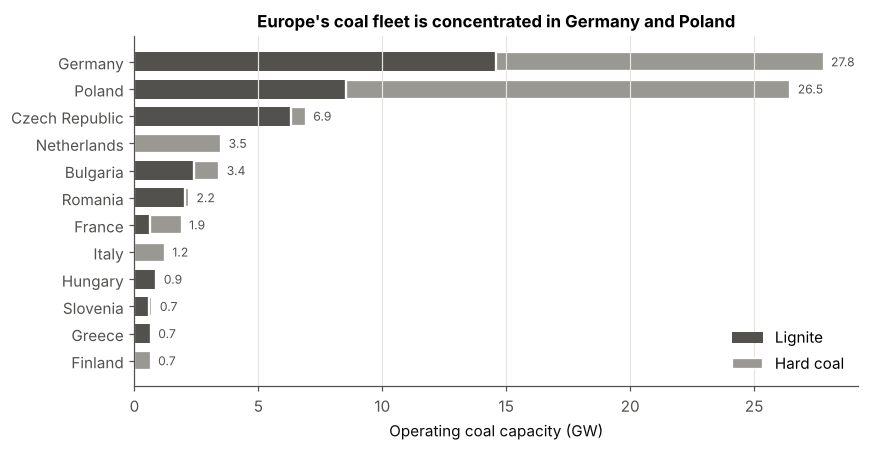

In [4]:
coal_eu = eu[(eu.Type == "coal") & (eu.Status == "operating")].copy()
# small data fix: a few units are 'operating' but their retirement year is already past -> treat as retired
stale = coal_eu["Retired year"] <= 2025
print(f"operating coal units with a retirement year <= 2025 (dropped): {stale.sum()} "
      f"({coal_eu.loc[stale, 'Capacity (MW)'].sum() / 1000:.1f} GW)")
coal_eu = coal_eu[~stale]

by_country = (coal_eu.pivot_table(index="Country/area", columns="coal_kind", values="Capacity (MW)",
                                  aggfunc="sum", fill_value=0) / 1000)
by_country["total"] = by_country.sum(axis=1)
by_country = by_country.sort_values("total", ascending=False)
top = by_country.head(12)
print(f"Operating coal in Europe: {by_country.total.sum():.1f} GW, "
      f"of which Germany {by_country.loc['Germany', 'total']:.1f} GW and Poland {by_country.loc['Poland', 'total']:.1f} GW "
      f"({(by_country.loc[['Germany', 'Poland'], 'total'].sum() / by_country.total.sum()):.0%} together)")

fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(top))[::-1]
ax.barh(y, top["lignite"], color="#52514e", height=0.7, label="Lignite")
ax.barh(y, top["hard coal"], left=top["lignite"], color=C["muted"], height=0.7, label="Hard coal",
        edgecolor="white", linewidth=1.5)
ax.set_yticks(y, top.index)
for yi, v in zip(y, top["total"]):
    ax.text(v + 0.3, yi, f"{v:.1f}", va="center", fontsize=8, color=C["ink2"])
ax.set(xlabel="Operating coal capacity (GW)", title="Europe's coal fleet is concentrated in Germany and Poland")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.tight_layout()
savefig(fig, "s1_coal_by_country")
plt.show()

## 1.2 The announced retirement schedule
We rebuild how much coal is left each year if every unit closes in its GEM retirement year (units with no date are assumed to keep running, as the project guidelines say). We also show how many GW actually *have* a date: a schedule is only as good as its coverage.

coal units with a retirement year: 64% of units, 75% of GW
coal left in 2030 if all dated units close: 44.4 GW of 77.5 GW (-43%); Germany 17.4 of 27.8 GW


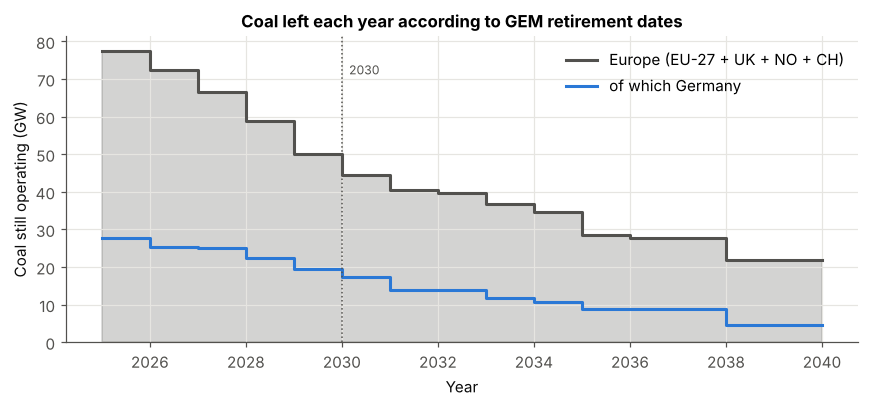

In [5]:
years_s = np.arange(2025, 2041)
left_dated = [coal_eu.loc[~(coal_eu["Retired year"] <= y), "Capacity (MW)"].sum() / 1000 for y in years_s]
dated_share = coal_eu["Retired year"].notna().mean()
dated_gw_share = coal_eu.loc[coal_eu["Retired year"].notna(), "Capacity (MW)"].sum() / coal_eu["Capacity (MW)"].sum()
de = coal_eu[coal_eu["Country/area"] == "Germany"]
left_de = [de.loc[~(de["Retired year"] <= y), "Capacity (MW)"].sum() / 1000 for y in years_s]
print(f"coal units with a retirement year: {dated_share:.0%} of units, {dated_gw_share:.0%} of GW")
print(f"coal left in 2030 if all dated units close: {left_dated[5]:.1f} GW of {left_dated[0]:.1f} GW "
      f"(-{1 - left_dated[5] / left_dated[0]:.0%}); Germany {left_de[5]:.1f} of {left_de[0]:.1f} GW")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.fill_between(years_s, left_dated, color="#52514e", alpha=0.25, step="post")
ax.step(years_s, left_dated, where="post", color="#52514e", lw=2, label="Europe (EU-27 + UK + NO + CH)")
ax.step(years_s, left_de, where="post", color=C["blue"], lw=2, label="of which Germany")
ax.axvline(2030, color=C["ink2"], ls=":", lw=1)
ax.text(2030.15, max(left_dated) * 0.92, "2030", color=C["ink2"], fontsize=8)
ax.set(xlabel="Year", ylabel="Coal still operating (GW)", ylim=(0, None),
       title="Coal left each year according to GEM retirement dates")
ax.legend()
plt.tight_layout()
savefig(fig, "s1_coal_schedule")
plt.show()

## 1.3 Which coal plants are the most exposed to carbon prices? (stranded-asset view)
Following *Question 1* of the project resources: carbon cost = emissions × carbon price, for **€50 / €82 / €100 / €150 per tCO₂** (€82 ≈ the EUA Dec-26 price in late August 2026, S&P Global Platts). Emissions = capacity × capacity factor (mode) × emission factor. We rank plants by absolute cost and by intensity (€ per MWh produced, i.e. how much the carbon price adds to the cost of each MWh).

yearly carbon bill of Europe's operating coal fleet (bn EUR): {50: np.float64(17.3), 82: np.float64(28.4), 100: np.float64(34.6), 150: np.float64(51.9)}
RWE plants in the top 10: 2 -> Niederaussem, Neurath


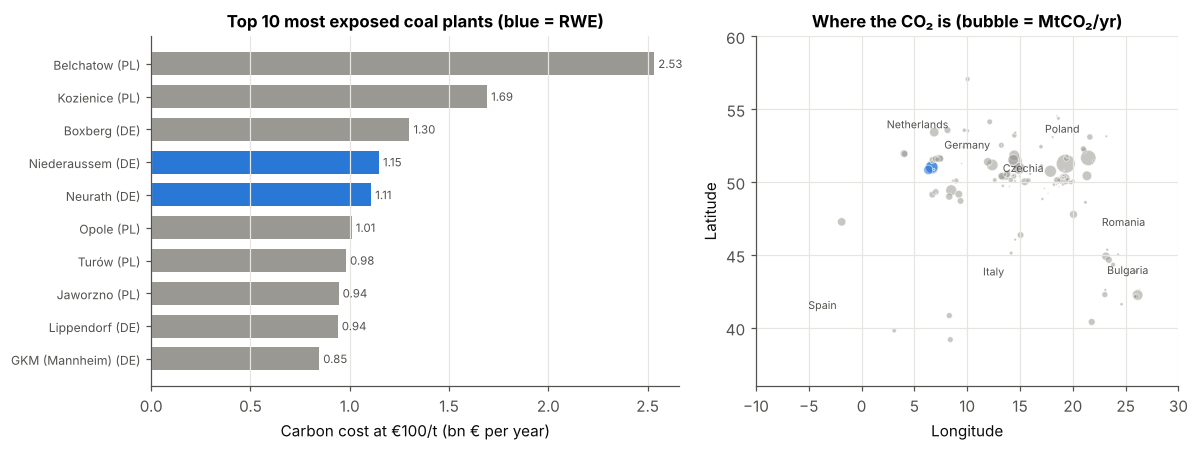

,Plant / Project name,Country/area,kind,GW,MtCO2,bnEUR_82,bnEUR_100,EUR_per_MWh_at_100,is_RWE
3,Belchatow power station,Poland,lignite,5.03,25.34,2.08,2.53,115.00,False
43,Kozienice power station,Poland,hard coal,3.99,16.92,1.39,1.69,96.73,False
9,Boxberg power station,Germany,lignite,2.58,13.01,1.07,1.30,115.00,False
64,Niederaussem power station,Germany,lignite,2.28,11.47,0.94,1.15,115.00,True
63,Neurath power station,Germany,lignite,2.20,11.08,0.91,1.11,115.00,True
69,Opole power station,Poland,hard coal,2.56,10.10,0.83,1.01,90.00,False
112,Turów power station,Poland,lignite,1.95,9.81,0.80,0.98,115.00,False
37,Jaworzno power station,Poland,hard coal,2.40,9.44,0.77,0.94,90.00,False
49,Lippendorf power station,Germany,lignite,1.87,9.40,0.77,0.94,115.00,False
25,GKM (Mannheim) power station,Germany,hard coal,2.15,8.46,0.69,0.85,90.00,False


In [6]:
PRICES = [50, 82, 100, 150]
coal_eu["ef"] = coal_eu["coal_kind"].map(EF)
coal_eu["twh"] = coal_eu["Capacity (MW)"] / 1000 * CF_MODE["coal"] * H_YEAR
coal_eu["mt"] = coal_eu["twh"] * coal_eu["ef"]
for p in PRICES:
    coal_eu[f"cost_{p}"] = coal_eu["mt"] * p / 1000          # bn EUR per year
plants = (coal_eu.groupby(["Plant / Project name", "Country/area"])
          .agg(GW=("Capacity (MW)", lambda s: s.sum() / 1000), MtCO2=("mt", "sum"),
               kind=("coal_kind", "first"), owner=("Owner(s)", "first"),
               lat=("Latitude", "mean"), lon=("Longitude", "mean"),
               **{f"bnEUR_{p}": (f"cost_{p}", "sum") for p in PRICES})
          .reset_index().sort_values("MtCO2", ascending=False))
plants["EUR_per_MWh_at_100"] = 100 * plants["MtCO2"] / (plants["GW"] * CF_MODE["coal"] * H_YEAR)
plants["is_RWE"] = plants["owner"].fillna("").str.contains(r"\bRWE\b")
total_cost = {p: coal_eu[f"cost_{p}"].sum() for p in PRICES}
print("yearly carbon bill of Europe's operating coal fleet (bn EUR):", {p: round(v, 1) for p, v in total_cost.items()})
top10 = plants.head(10)
print(f"RWE plants in the top 10: {top10.is_RWE.sum()} -> "
      f"{', '.join(top10.loc[top10.is_RWE, 'Plant / Project name'].str.replace(' power station', ''))}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
yy = np.arange(len(top10))[::-1]
cols = [C["blue"] if r else C["muted"] for r in top10.is_RWE]
ax.barh(yy, top10["bnEUR_100"], color=cols, height=0.7)
ISO = {"Poland": "PL", "Germany": "DE", "Czech Republic": "CZ", "Bulgaria": "BG", "Romania": "RO", "Netherlands": "NL"}
ax.set_yticks(yy, [f"{n.replace(' power station', '').replace(' Power Station', '')} ({ISO.get(c, c[:2].upper())})"
                   for n, c in zip(top10["Plant / Project name"], top10["Country/area"])], fontsize=8)
for yi, v in zip(yy, top10["bnEUR_100"]):
    ax.text(v + 0.02, yi, f"{v:.2f}", va="center", fontsize=7.5, color=C["ink2"])
ax.set(xlabel="Carbon cost at €100/t (bn € per year)", title="Top 10 most exposed coal plants (blue = RWE)")
ax.grid(axis="y", visible=False)
ax = axes[1]
sc = ax.scatter(plants["lon"], plants["lat"], s=plants["MtCO2"] * 6, alpha=0.55,
                c=np.where(plants.is_RWE, C["blue"], C["muted"]), edgecolor="white", linewidth=0.6)
for nm, (lo, la) in {"Germany": (10.0, 51.2), "Poland": (19.0, 52.3), "Czechia": (15.3, 49.6), "Bulgaria": (25.2, 42.6),
                     "Netherlands": (5.3, 52.6), "Spain": (-3.7, 40.2), "Italy": (12.5, 42.5), "Romania": (24.8, 45.9)}.items():
    ax.text(lo, la + 1.1, nm, fontsize=7, color=C["ink2"], ha="center")
ax.set(xlim=(-10, 30), ylim=(36, 60), xlabel="Longitude", ylabel="Latitude",
       title="Where the CO₂ is (bubble = MtCO₂/yr)")
plt.tight_layout()
savefig(fig, "s1_stranded_assets")
plt.show()
plants.head(10)[["Plant / Project name", "Country/area", "kind", "GW", "MtCO2", "bnEUR_82", "bnEUR_100",
                 "EUR_per_MWh_at_100", "is_RWE"]]

**Reading.** Lignite plants dominate the top of the ranking: they are big *and* they have the highest emission factor, so at €100/t the carbon price alone adds **about €115 per MWh** to a lignite MWh (vs ~€90 for hard coal). That is more than the average German wholesale price in normal years, which is the economic reason the coal exit is happening at all. RWE's Rhineland plants (Niederaussem, Neurath, Weisweiler) are among the most exposed assets in Europe.

## 1.4 Country level: does the utility-scale pipeline cover the coal?

We apply the metric to whole countries (no ownership needed, so it is more robust than at company level). Each pipeline project is weighted by its probability of being online by 2030, using the **sector base rates** of Part 0 (construction 0.95; dated pre-construction = GEM-wide build rate × 0.8; dated announced = half of that; undated projects = 0). Because ratios explode when little coal is left (a country with 0.7 GW of coal can show a ratio of 30), we plot the **gap in TWh** (expected new wind + solar output − coal output) instead of the ratio.

countries with >= 0.5 GW coal: expected new wind+solar 91 TWh/yr vs coal 334 TWh/yr (ratio 0.27)


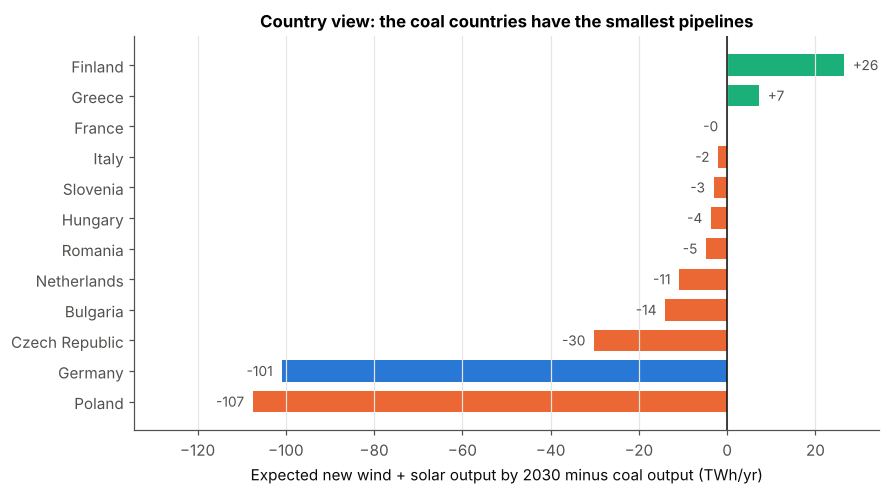

,country,coal_GW,coal_TWh,pipeline_GW_dated,exp_new_RE_TWh,gap_TWh,ratio
9,Poland,26.46,115.90,10.89,8.46,-107.43,0.07
4,Germany,27.80,121.77,23.37,20.82,-100.96,0.17
1,Czech Republic,6.91,30.28,0.08,0.16,-30.12,0.01
0,Bulgaria,3.42,15.00,1.01,1.01,-13.99,0.07
8,Netherlands,3.50,15.33,9.81,4.51,-10.82,0.29
10,Romania,2.20,9.64,3.20,4.89,-4.75,0.51
6,Hungary,0.88,3.87,0.43,0.25,-3.63,0.06
11,Slovenia,0.72,3.17,0.28,0.16,-3.01,0.05
7,Italy,1.23,5.39,5.64,3.40,-1.99,0.63
3,France,1.91,8.35,7.88,8.32,-0.03,1.00


In [7]:
rows = []
for c, g in eu.groupby("Country/area"):
    coal_gw = coal_eu.loc[coal_eu["Country/area"] == c, "Capacity (MW)"].sum() / 1000
    if coal_gw < 0.5:
        continue
    rows.append({"country": c, "coal_GW": coal_gw, "coal_TWh": coal_gw * CF_MODE["coal"] * H_YEAR,
                 "pipeline_GW_dated": g.loc[g.Type.isin(RE) & g.Status.isin(PIPE_STATUS) & (g["Start year"] <= TARGET),
                                            "Capacity (MW)"].sum() / 1000,
                 "exp_new_RE_TWh": expected_pipeline_twh(g)})
ctry = pd.DataFrame(rows)
ctry["gap_TWh"] = ctry.exp_new_RE_TWh - ctry.coal_TWh
ctry["ratio"] = ctry.exp_new_RE_TWh / ctry.coal_TWh
ctry = ctry.sort_values("gap_TWh")
eu_ratio = ctry.exp_new_RE_TWh.sum() / ctry.coal_TWh.sum()
print(f"countries with >= 0.5 GW coal: expected new wind+solar {ctry.exp_new_RE_TWh.sum():.0f} TWh/yr "
      f"vs coal {ctry.coal_TWh.sum():.0f} TWh/yr (ratio {eu_ratio:.2f})")

fig, ax = plt.subplots(figsize=(8.2, 4.6))
yy = np.arange(len(ctry))
cols = [C["blue"] if c == "Germany" else (C["orange"] if gp < 0 else C["aqua"]) for c, gp in zip(ctry.country, ctry.gap_TWh)]
ax.barh(yy, ctry.gap_TWh, color=cols, height=0.7)
ax.axvline(0, color=C["ink"], lw=1)
ax.set_yticks(yy, ctry.country, fontsize=10)
for yi, (gp, cg) in enumerate(zip(ctry.gap_TWh, ctry.coal_TWh)):
    ax.text(gp + (2 if gp >= 0 else -2), yi, f"{gp:+.0f}", va="center", ha="left" if gp >= 0 else "right",
            fontsize=9, color=C["ink2"])
ax.set(xlabel="Expected new wind + solar output by 2030 minus coal output (TWh/yr)",
       title="Country view: the coal countries have the smallest pipelines")
ax.set_xlim(ctry.gap_TWh.min() * 1.25, max(ctry.gap_TWh.max() * 1.3, 20))
ax.grid(axis="y", visible=False)
plt.tight_layout()
savefig(fig, "s1_country_gap")
plt.show()
ctry.round(2)

## 1.5 Peer utilities, European assets only
For each large European utility we keep the units **located in Europe** (EU-27 + UK + NO + CH) where the company or a subsidiary appears as owner or parent, weighted by **equity share** (sum of the % next to the company's entities; equal split if no % is given). Same yardstick for everybody: all operating coal in Europe. GEM ownership is incomplete for every company (see `parent_coverage`), so this is context, not a ranking.

In [8]:
PEERS = {"RWE": r"\bRWE\b", "EnBW": r"\bEnBW\b", "Uniper": r"Uniper", "LEAG / EPH": r"Lausitz Energie|LEAG|Energetický a průmyslový|EP Investment",
         "PGE": r"\bPGE\b", "ENEA": r"\bENEA\b", "TAURON": r"TAURON|Tauron", "CEZ": r"\bCEZ\b|ČEZ",
         "Enel (incl. Endesa)": r"\bEnel\b|Endesa", "Engie": r"ENGIE|Engie", "EDF": r"Electricit[ée] de France|\bEDF\b",
         "Fortum": r"Fortum", "Iberdrola": r"Iberdrola|ScottishPower|Avangrid", "Orsted": r"Ørsted|Orsted",
         "Vattenfall": r"Vattenfall", "EDP": r"\bEDP\b"}


def equity_share(owner, parent, rx):
    """share of the company in a unit: parent column first (already consolidated), owner column otherwise."""
    txt = parent if re.search(rx, str(parent)) else owner
    parts = [p.strip() for p in str(txt).split(";") if p.strip()]
    shares = []
    for p in parts:
        if re.search(rx, p):
            m = re.search(r"\[([\d.]+)%\]", p)
            if m is None:
                return 1 / len(parts)
            shares.append(float(m.group(1)) / 100)
    return min(sum(shares), 1.0)


def company_units(rx, df=gipt):
    m = df["Owner(s)"].fillna("").str.contains(rx) | df["Parent(s)"].fillna("").str.contains(rx)
    out = df[m].copy()
    out["w"] = [equity_share(o, p, rx) for o, p in zip(out["Owner(s)"], out["Parent(s)"])]
    out["mw_eq"] = out["Capacity (MW)"] * out["w"]
    return out


peer_rows = []
for name, rx in PEERS.items():
    u = company_units(rx, df=eu)
    op_ = u[(u.Status == "operating") & ~(u["Retired year"] <= 2025)]
    coal_gw = op_.loc[op_.Type == "coal", "mw_eq"].sum() / 1000
    peer_rows.append({
        "company": name, "units_in_Europe": len(u), "parent_coverage": u["Parent(s)"].notna().mean(),
        "coal_GW": coal_gw, "gas_GW": op_.loc[op_.Type == "oil/gas", "mw_eq"].sum() / 1000,
        "wind_solar_GW": op_.loc[op_.Type.isin(RE), "mw_eq"].sum() / 1000,
        "exp_new_RE_TWh": expected_pipeline_twh(u), "coal_TWh": coal_gw * CF_MODE["coal"] * H_YEAR})
peers = pd.DataFrame(peer_rows)
# harmonise RWE with Part 2: add Eemshaven (owned by RWE, listed under E.ON in GEM), coal share 0.75.
# All peers keep the same uncalibrated coal CF (0.50): this is a sector yardstick; Part 2 uses RWE's calibrated CF.
_eems_gw = gipt.loc[gipt["Plant / Project name"].eq("Eemshaven power station") & gipt.Type.eq("coal"), "Capacity (MW)"].sum() / 1000 * 0.75
peers.loc[peers.company == "RWE", "coal_GW"] += _eems_gw
peers["coal_TWh"] = peers.coal_GW * CF_MODE["coal"] * H_YEAR
peers["gap_TWh"] = peers.exp_new_RE_TWh - peers.coal_TWh
peers["ratio"] = np.where(peers.coal_TWh > 2, peers.exp_new_RE_TWh / peers.coal_TWh.where(peers.coal_TWh > 2), np.nan)
peers = peers.sort_values("coal_GW", ascending=False)
peers.round(2)

,company,units_in_Europe,parent_coverage,coal_GW,gas_GW,wind_solar_GW,exp_new_RE_TWh,coal_TWh,gap_TWh,ratio
4,PGE,138,0.70,11.81,2.30,0.86,0.78,51.72,-50.94,0.02
0,RWE,430,0.33,7.92,15.18,5.97,6.29,34.71,-28.42,0.18
5,ENEA,38,0.84,5.76,0.01,0.11,0.00,25.23,-25.23,0.00
1,EnBW,158,0.28,5.59,1.93,2.20,3.93,24.49,-20.56,0.16
3,LEAG / EPH,164,0.91,5.02,12.50,0.11,0.66,21.99,-21.33,0.03
6,TAURON,79,0.72,4.42,0.30,0.57,0.22,19.37,-19.16,0.01
7,CEZ,79,0.62,3.00,0.90,0.14,0.09,13.13,-13.04,0.01
2,Uniper,121,0.71,2.39,10.04,0.00,0.22,10.48,-10.26,0.02
10,EDF,507,0.15,1.26,5.44,3.89,2.65,5.52,-2.87,0.48
8,Enel (incl. Endesa),695,0.26,0.85,15.76,7.00,4.11,3.72,0.39,1.11


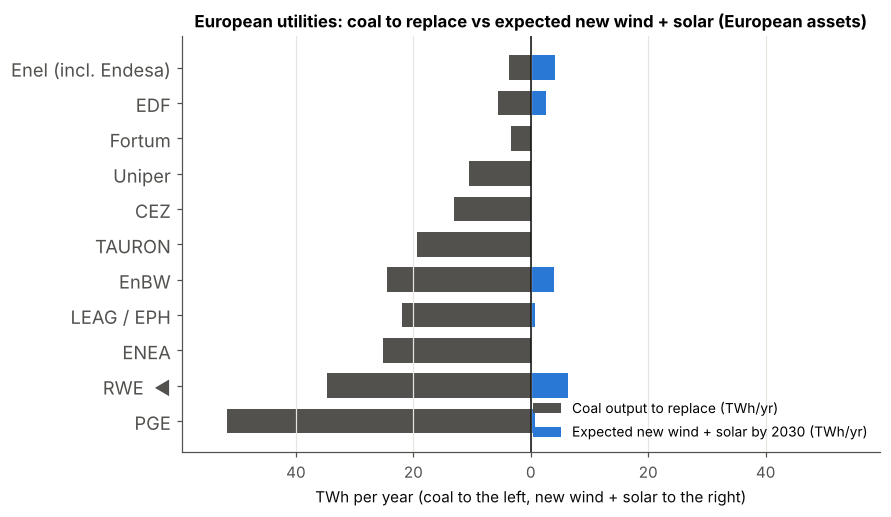

In [9]:
pc = peers[peers.coal_GW >= 0.5].sort_values("gap_TWh").copy()
fig, ax = plt.subplots(figsize=(8.2, 4.8))
yy = np.arange(len(pc))
ax.barh(yy, -pc.coal_TWh, color="#52514e", height=0.7, label="Coal output to replace (TWh/yr)")
ax.barh(yy, pc.exp_new_RE_TWh, color=C["blue"], height=0.7, label="Expected new wind + solar by 2030 (TWh/yr)")
ax.axvline(0, color=C["ink"], lw=1)
ax.set_yticks(yy, [f"{c}{'  ◀' if c == 'RWE' else ''}" for c in pc.company], fontsize=12)
xmax = max(pc.exp_new_RE_TWh.max(), pc.coal_TWh.max()) * 1.15
ax.set_xlim(-xmax, xmax)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{abs(v):.0f}"))
ax.set(xlabel="TWh per year (coal to the left, new wind + solar to the right)",
       title="European utilities: coal to replace vs expected new wind + solar (European assets)")
ax.legend(loc="lower right", fontsize=9)
ax.grid(axis="y", visible=False)
plt.tight_layout()
savefig(fig, "s1_peers")
plt.show()

**Sector takeaways.**
* About 70% of Europe's operating coal is in Germany and Poland, and lignite is the asset class most exposed to the carbon price.
* GEM retirement dates cover 75% of the coal GW. If they are all respected, 43% of Europe's coal closes by 2030.
* The countries with the most coal have the largest TWh gap: in Germany and Poland the dated utility-scale pipeline covers only a small part of coal output (GEM does not track rooftop solar, so the gap is overstated, but the ranking holds).
* Among European utilities, the large Central-European coal owners have almost no dated wind and solar pipeline. RWE has the largest expected new output among the coal owners, but on its European assets alone it still covers only about a fifth of its coal output; the worldwide portfolio view is in Part 2.

---
# Part 2. RWE

## 2.1 Data audit and the corrections it forces

In [10]:
rwe = company_units(PEERS["RWE"])          # all RWE units worldwide (portfolio metric)
audit = pd.Series({
    "units linked to RWE": len(rwe),
    "share with capacity": rwe["Capacity (MW)"].notna().mean(),
    "share with parent recorded": rwe["Parent(s)"].notna().mean(),
    "share with an RWE entity in the owner column": rwe["Owner(s)"].fillna("").str.contains("RWE").mean(),
    "share of built wind/solar MW with start year": (
        rwe.loc[rwe.Type.isin(RE) & rwe.Status.isin(["operating", "retired"])]
        .pipe(lambda d: d.loc[d["Start year"].notna(), "mw_eq"].sum() / d["mw_eq"].sum())),
    "share of operating fossil units with retirement date": (
        rwe.loc[rwe.Type.isin(FOSSIL) & (rwe.Status == "operating"), "Retired year"].notna().mean()),
    "share of RWE wind/solar pipeline MW with a start year": (
        rwe.loc[rwe.Type.isin(RE) & rwe.Status.isin(PIPE_STATUS)]
        .pipe(lambda d: d.loc[d["Start year"].notna(), "mw_eq"].sum() / d["mw_eq"].sum())),
})
print(audit.round(2).to_string())

units linked to RWE                                     522.00
share with capacity                                       1.00
share with parent recorded                                0.28
share with an RWE entity in the owner column              0.98
share of built wind/solar MW with start year              0.98
share of operating fossil units with retirement date      0.19
share of RWE wind/solar pipeline MW with a start year     0.34


**What the audit changes.**

1. **Ownership coverage.** Only 28% of RWE units have a parent recorded, below the 70% bar we set in V0. We keep RWE because 98% of the matched units name an RWE entity directly as owner, but GEM sees only about 64% of the wind and solar capacity RWE reports for end 2024 (11.6 GW vs 18.0 GW pro rata, RWE Annual Report 2024). We therefore report results on **two bases** throughout: *GEM-visible* and *coverage-adjusted* (÷ 0.64), and we never compare numbers across bases.
2. **Eemshaven.** GEM lists the Eemshaven hard-coal plant (Netherlands; GEM: 2 × 800 MW, RWE quotes 1,560-1,580 MW) under Essent NV / E.ON SE, a leftover of the 2019 E.ON-RWE asset swap. The plant is RWE's, and RWE says it will stop using coal there by 2030 at the latest. We add it back at 100%, counting 75% of its output as coal (25% of its energy already comes from biomass, RWE Benelux).
3. **Dates in GEM vs the law.** GEM dates Neurath F and G to 2033 (the possible reserve), while the law and the 2022 agreement end lignite power on 31 March 2030. Main case = contract; reserve = sensitivity. In August 2026 the economy ministry let the review deadline pass without a decision (Clean Thinking, 13 Aug 2026). We also drop Weisweiler F, "operating" in GEM with a retirement year (2024) already past.
4. **The pipeline is mostly undated, and GEM statuses lag reality.** Only part of RWE's pipeline MW has a start year. Several offshore projects listed as "pre-construction" are in fact under construction (Nordseecluster A and B, Thor, OranjeWind), one was sold (F.E.W. Baltic II, to PGE), and others have public commissioning dates after 2030. Because offshore drives the result, we check every RWE offshore project against public sources (Part 2.5).

In [11]:
# ---- manual ownership correction: Eemshaven (GEM lists Essent / E.ON, the plant is RWE's)
eems = gipt[gipt["Plant / Project name"].eq("Eemshaven power station") & gipt.Type.eq("coal")].copy()
eems["w"] = 1.0
eems["mw_eq"] = eems["Capacity (MW)"]
EEMS_COAL_SHARE = 0.75                       # 25% of energy already from biomass (RWE Benelux)
rwe = pd.concat([rwe, eems])
rwe["corrected"] = rwe.index.isin(eems.index)
print(f"added Eemshaven: {eems['Capacity (MW)'].sum():.0f} MW in GEM (owner in GEM: {eems['Owner(s)'].iloc[0]})")

RWE_REPORTED_2024 = 3.3 + 9.0 + 5.7         # offshore + onshore + solar, pro rata, end 2024 (RWE Annual Report 2024)

added Eemshaven: 1600 MW in GEM (owner in GEM: Essent NV [100%])


## 2.2 RWE's portfolio today and its coal fleet unit by unit

In [12]:
op = rwe[(rwe.Status == "operating") & ~(rwe["Retired year"] <= 2025)].copy()
op["fuel"] = np.select([op.Type.eq("coal"), op.Type.eq("oil/gas"), op.Type.eq("wind"),
                        op.Type.eq("utility-scale solar")], ["coal", "gas", "wind", "solar"], "other")
mix = op.groupby("fuel")["mw_eq"].sum().div(1000).reindex(["coal", "gas", "wind", "solar", "other"]).fillna(0)
print("RWE operating capacity in GEM, equity share (GW):", mix.round(2).to_dict(), f"| total {mix.sum():.1f} GW")

# coal units with the date they close under the CONTRACT (main case) and under the RESERVE option
coal = op[op.Type == "coal"].copy()
coal["kind"] = coal["coal_kind"]
coal["coal_mw"] = coal["mw_eq"] * np.where(coal.corrected, EEMS_COAL_SHARE, 1.0)
coal["plant"] = coal["Plant / Project name"].str.replace(" power station", "").str.replace(" (Mannheim)", "")
coal["label"] = coal["plant"] + " " + coal["Unit / Phase name"].str.replace("Unit ", "").str.replace("Mannheim ", "").str.replace("Phase ", "")
lignite_rhine = coal.kind.eq("lignite")
coal["close_contract"] = np.where(lignite_rhine, np.minimum(coal["Retired year"].fillna(2030), 2030),
                                  coal["Retired year"].fillna(2030))
# reserve option: the three 1 GW-class units (Niederaussem K, Neurath F, G) stay available until end 2033
coal["is_reserve_unit"] = coal.label.isin(["Niederaussem K", "Neurath F", "Neurath G"])
coal["close_reserve"] = np.where(coal.is_reserve_unit, 2033, coal["close_contract"])
coal_table = coal[["label", "kind", "Capacity (MW)", "w", "coal_mw", "Start year", "Retired year",
                   "close_contract", "close_reserve"]].sort_values(["close_contract", "label"])
print(f"coal to close (equity, coal part): {coal.coal_mw.sum() / 1000:.2f} GW "
      f"(of which Eemshaven {coal.loc[coal.corrected, 'coal_mw'].sum() / 1000:.2f} GW, "
      f"GKM Mannheim 40% stake {coal.loc[coal.plant.str.contains('GKM'), 'coal_mw'].sum() / 1000:.2f} GW)")
coal_table

RWE operating capacity in GEM, equity share (GW): {'coal': 8.32, 'gas': 15.74, 'wind': 11.0, 'solar': 1.85, 'other': 2.25} | total 39.2 GW
coal to close (equity, coal part): 7.92 GW (of which Eemshaven 1.20 GW, GKM Mannheim 40% stake 0.86 GW)


,label,kind,Capacity (MW),w,coal_mw,Start year,Retired year,close_contract,close_reserve
154517,Weisweiler G,lignite,630.00,1.00,630.00,"1,974.00","2,028.00","2,028.00","2,028.00"
157869,Eemshaven 1,hard coal,800.00,1.00,600.00,"2,015.00","2,029.00","2,029.00","2,029.00"
157870,Eemshaven 2,hard coal,800.00,1.00,600.00,"2,015.00","2,029.00","2,029.00","2,029.00"
154455,Niederaussem G,lignite,630.00,1.00,630.00,"1,974.00","2,029.00","2,029.00","2,029.00"
154518,Weisweiler H,lignite,625.00,1.00,625.00,"1,975.00","2,029.00","2,029.00","2,029.00"
154375,GKM 6,hard coal,280.00,0.40,112.00,"1,975.00",NaN,"2,030.00","2,030.00"
154378,GKM 9,hard coal,912.00,0.40,364.80,"2,015.00",NaN,"2,030.00","2,030.00"
154379,Goldenberg E,lignite,76.00,1.00,76.00,"1,992.00",NaN,"2,030.00","2,030.00"
154405,Huerth Ville / Berrenrath --,lignite,57.00,1.00,57.00,"1,991.00",NaN,"2,030.00","2,030.00"
154447,Neurath F,lignite,"1,100.00",1.00,"1,100.00","2,012.00","2,033.00","2,030.00","2,033.00"


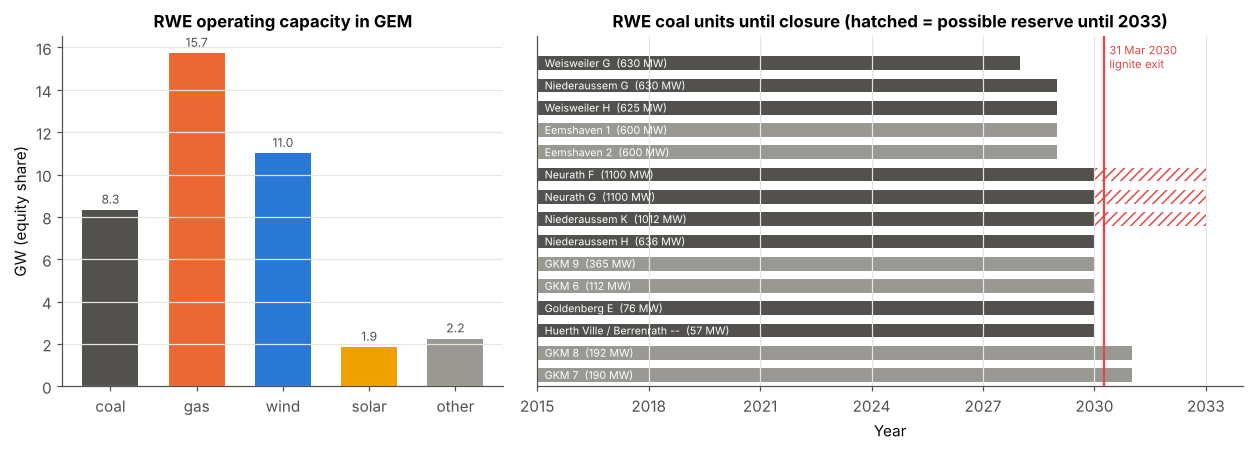

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
order = ["coal", "gas", "wind", "solar", "other"]
ax.bar(order, mix[order], color=[FUEL_COL[f] for f in order], width=0.65)
for i, v in enumerate(mix[order]):
    ax.text(i, v + 0.3, f"{v:.1f}", ha="center", fontsize=8, color=C["ink2"])
ax.set(ylabel="GW (equity share)", title="RWE operating capacity in GEM")
ax.grid(axis="x", visible=False)

ax = axes[1]
ct = coal.sort_values(["close_contract", "coal_mw"], ascending=[True, False]).reset_index(drop=True)
for i, r in ct.iterrows():
    start = max(r["Start year"], 2015)
    ax.barh(i, r.close_contract - start, left=start, height=0.62,
            color="#52514e" if r.kind == "lignite" else C["muted"])
    if r.close_reserve > r.close_contract:
        ax.barh(i, r.close_reserve - r.close_contract, left=r.close_contract, height=0.62,
                color="none", edgecolor=C["red"], hatch="////", linewidth=0)
    ax.text(2015.2, i, f"{r.label}  ({r.coal_mw:.0f} MW)", va="center", fontsize=7, color="white")
ax.axvline(2030.25, color=C["red"], lw=1.5)
ax.text(2030.4, -0.9, "31 Mar 2030\nlignite exit", fontsize=7.5, color=C["red"], va="top")
ax.set_xticks(range(2015, 2035, 3))
ax.set(xlim=(2015, 2034), ylim=(len(ct) - 0.5, -1.2), yticks=[], xlabel="Year",
       title="RWE coal units until closure (hatched = possible reserve until 2033)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
savefig(fig, "r1_portfolio_coal_timeline")
plt.show()

## 2.3 History: how fast did RWE's wind + solar fleet grow?
We rebuild RWE's operating wind + solar capacity year by year from the start years of the units it owns today (equity share). This is a **back-projection**: assets bought later (E.ON swap 2019, Con Edison Clean Energy 2023) appear as if RWE built them, and assets sold since disappear. We show it on both bases: GEM-visible, and coverage-adjusted (÷ 0.64, assuming GEM misses the same share of every vintage).

In [14]:
built = rwe[rwe.Type.isin(RE) & rwe.Status.isin(["operating", "retired"]) & rwe["Start year"].notna()]
NOW = 2025                                  # last complete year in GEM (2026 is not complete in a Sept 2026 file)
years = np.arange(2005, NOW + 1)
hist = pd.DataFrame({"year": years})
hist["capacity_GW"] = [built.loc[(built["Start year"] <= y) & ~(built["Retired year"] <= y), "mw_eq"].sum() / 1000
                       for y in years]
hist["additions_GW"] = [built.loc[built["Start year"] == y, "mw_eq"].sum() / 1000 for y in years]
cap_now = hist.set_index("year").loc[NOW, "capacity_GW"]
COVERAGE = hist.set_index("year").loc[2024, "capacity_GW"] / RWE_REPORTED_2024
hist["additions_adj_GW"] = hist.additions_GW / COVERAGE
roll3 = hist.additions_GW.rolling(3).mean()
pace = pd.DataFrame({
    "GEM-visible": {"last 10 years": hist.additions_GW.tail(10).mean(), "last 4 years": hist.additions_GW.tail(4).mean(),
                    "best 3-year average": roll3.max()},
})
pace["coverage-adjusted"] = pace["GEM-visible"] / COVERAGE
print(f"wind + solar in GEM, end {NOW}: {cap_now:.2f} GW | GEM sees {COVERAGE:.0%} of RWE's reported 2024 capacity")
print(f"best 3-year average in GEM: {roll3.max():.2f} GW/yr ({int(hist.year[roll3.idxmax()]) - 2}-{int(hist.year[roll3.idxmax()])})")
pace.round(2)

wind + solar in GEM, end 2025: 12.64 GW | GEM sees 64% of RWE's reported 2024 capacity
best 3-year average in GEM: 1.26 GW/yr (2021-2023)


,GEM-visible,coverage-adjusted
last 10 years,0.78,1.22
last 4 years,1.01,1.56
best 3-year average,1.26,1.95


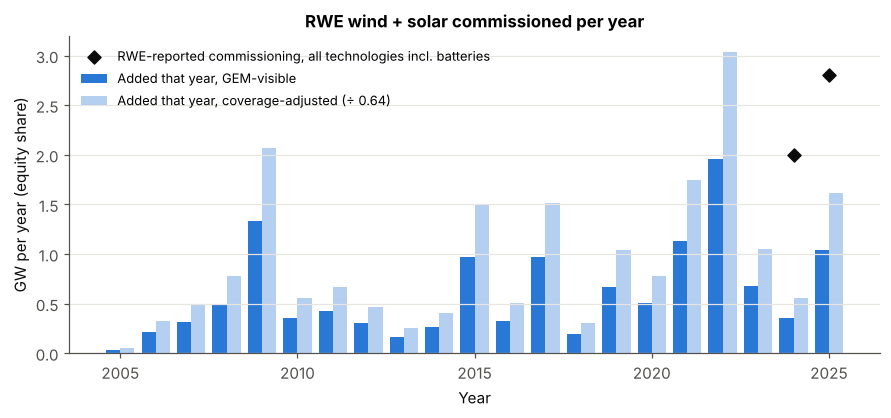

In [15]:
fig, ax = plt.subplots(figsize=(8.2, 3.9))
ax.bar(hist.year - 0.2, hist.additions_GW, width=0.4, color=C["blue"], label="Added that year, GEM-visible")
ax.bar(hist.year + 0.2, hist.additions_adj_GW, width=0.4, color=C["blue"], alpha=0.35, label="Added that year, coverage-adjusted (÷ 0.64)")
ax.scatter([2024, 2025], [2.0, 2.8], color=C["ink"], marker="D", s=36, zorder=4,
           label="RWE-reported commissioning, all technologies incl. batteries")
ax.set(xlabel="Year", ylabel="GW per year (equity share)", title="RWE wind + solar commissioned per year")
ax.legend(loc="upper left", fontsize=8.5)
ax.grid(axis="x", visible=False)
plt.tight_layout()
savefig(fig, "r2_history")
plt.show()

## 2.4 Calibrating plant utilisation on reported emissions
Before computing the metric we check our capacity factors against what RWE reports. Modelled emissions in year *t* = Σ (fossil units operating in *t*) × equity GW × CF × emission factor. We use RWE's **official Scope 1 GHG emissions** for the five years it publishes in the same series: 2019 = 91.7, 2021 = 86.9, 2022 = 85.4, 2023 = 61.9, 2025 = 51.9 MtCO₂e (RWE Factbook 2026, p. 13; Sustainability Performance Report 2023). We fit `reported = B × modelled` through the origin (no plants, no emissions) and estimate the standard error of B, so that B can be drawn in the Monte Carlo instead of being a fixed constant.

B absorbs every difference between model and reality: capacity factors, emission factors, and Scope 1 sources other than power plants (mining, own use). When we apply B to *output* (TWh) as well, we assume most of the gap comes from utilisation; this is an assumption, discussed in the limitations.

In [16]:
REPORTED = pd.Series({2019: 91.7, 2021: 86.9, 2022: 85.4, 2023: 61.9, 2025: 51.9}, name="reported_Mt")   # RWE Scope 1, MtCO2e
fossil_all = rwe[rwe.Type.isin(FOSSIL) & rwe.Status.isin(["operating", "retired", "mothballed"]) & rwe["Start year"].notna()].copy()
fossil_all["ef"] = np.where(fossil_all.Type.eq("oil/gas"), EF["gas"], fossil_all.coal_kind.map(EF))
fossil_all["cf"] = np.where(fossil_all.Type.eq("oil/gas"), CF_MODE["gas"], CF_MODE["coal"])
fossil_all["share_fossil"] = np.where(fossil_all.corrected, EEMS_COAL_SHARE, 1.0)


def modelled(year, df=fossil_all):
    d = df[(df["Start year"] <= year) & ~(df["Retired year"] < year)]
    gw = d.mw_eq / 1000 * d.share_fossil
    return float((gw * d.cf * d.ef).sum() * H_YEAR), float((gw * d.cf).sum() * H_YEAR)   # Mt, TWh


calib = pd.DataFrame({"modelled_Mt": [modelled(y)[0] for y in REPORTED.index],
                      "modelled_TWh": [modelled(y)[1] for y in REPORTED.index]}, index=REPORTED.index).join(REPORTED)
x_, y_ = calib.modelled_Mt.to_numpy(), calib.reported_Mt.to_numpy()
B = float((x_ * y_).sum() / (x_ * x_).sum())
calib["fitted_Mt"] = B * calib.modelled_Mt
calib["residual_Mt"] = calib.reported_Mt - calib.fitted_Mt
calib.index.name = "year"
B_SE = float(np.sqrt((calib.residual_Mt ** 2).sum() / (len(calib) - 1) / (x_ ** 2).sum()))
B_R2 = 1 - (calib.residual_Mt ** 2).sum() / ((y_ - y_.mean()) ** 2).sum()
B_CI = (B - stats.t.ppf(0.95, len(calib) - 1) * B_SE, B + stats.t.ppf(0.95, len(calib) - 1) * B_SE)
COAL_CF_EFF = CF_MODE["coal"] * B
B_DRAW = np.clip(np.random.default_rng(SEED + 7).normal(B, B_SE, N), 0.3, 1.5)   # used in the Monte Carlo
print(f"reported = {B:.2f} x modelled (n = {len(calib)}, RWE official Scope 1), se(B) = {B_SE:.3f}, "
      f"90% CI [{B_CI[0]:.2f}, {B_CI[1]:.2f}], R² = {B_R2:.2f}")
print(f"-> effective coal capacity factor used in the metric: {CF_MODE['coal']} x {B:.2f} = {COAL_CF_EFF:.2f}")
# cross-check with RWE's 2022 generation by fuel (RWE FY2022: lignite 50.0, hard coal 7.2, gas 51.7 TWh; total 156.8 TWh)
print(f"cross-check 2022: modelled fossil output x B = {calib.loc[2022, 'modelled_TWh'] * B:.0f} TWh "
      f"vs reported lignite + hard coal + gas = {50.0 + 7.2 + 51.7:.0f} TWh (RWE FY2022)")
calib.round(1)

reported = 0.92 x modelled (n = 5, RWE official Scope 1), se(B) = 0.046, 90% CI [0.83, 1.02], R² = 0.77
-> effective coal capacity factor used in the metric: 0.5 x 0.92 = 0.46
cross-check 2022: modelled fossil output x B = 99 TWh vs reported lignite + hard coal + gas = 109 TWh (RWE FY2022)


,modelled_Mt,modelled_TWh,reported_Mt,fitted_Mt,residual_Mt
year,,,,,
2019,102.80,132.60,91.70,95.10,-3.40
2021,91.70,120.60,86.90,84.80,2.10
2022,77.70,107.20,85.40,71.90,13.50
2023,76.00,106.10,61.90,70.30,-8.40
2025,60.70,92.30,51.90,56.10,-4.20


B < 1 means our mode capacity factors are too high on average, so we carry the calibration into the metric: the coal output to replace is computed with an effective coal capacity factor of 0.50 × B, and B is drawn from its sampling distribution in the Monte Carlo. With only five points the calibration is fragile: 2022 sits above the line (gas crisis, lignite ran flat out) and 2023-2025 below (cheaper gas, higher CO₂ price). Utilisation is the main source of uncertainty in power-sector emissions.

## 2.2bis The coal to replace
Coal output (TWh/yr) = Σ coal units × equity share × coal share × effective CF. We use **equity share** (RWE's economic exposure) rather than operational control. The two differ for GKM Mannheim (RWE 40%, operated by GKM itself: counted at 40% here, 0% under operational control) and for the offshore joint ventures RWE operates (counted at RWE's share here, 100% under operational control); both are in the sensitivities.

In [17]:
coal_gw_main = coal.coal_mw.sum() / 1000
coal_gw_noeems = coal.loc[~coal.corrected, "coal_mw"].sum() / 1000
coal_gw_nogkm = coal_gw_main - coal.loc[coal.plant.str.contains("GKM"), "coal_mw"].sum() / 1000
COAL_TWH = coal_gw_main * COAL_CF_EFF * H_YEAR
print(f"coal to close: {coal_gw_main:.2f} GW (equity, coal part) -> {COAL_TWH:.1f} TWh/yr at CF {COAL_CF_EFF:.2f}")

coal to close: 7.92 GW (equity, coal part) -> 32.1 TWh/yr at CF 0.46


## 2.5 The pipeline: GEM statuses checked against public evidence

**Rule for every project except RWE's offshore wind** (the same rule as the sector view, so no RWE-specific survival bias):
* under construction: p = 0.95;
* pre-construction **with a start year ≤ 2030**: p = GEM-wide build rate of the technology (MW that reached operation ÷ MW that reached operation or was cancelled/shelved, projects since 2015) × 0.8 for slippage;
* announced with a start year ≤ 2030: half of that;
* **undated** projects: p = 0 in the main case (they are a sensitivity).

Using sector-wide rates removes the survival bias of a rate computed on RWE's own assets (many were acquired operating and never faced the risk of cancellation at RWE). Multiplying P(built) × P(on time) assumes the two are independent. Sector rates have their own biases: (i) they only use *resolved* projects (built or abandoned), and projects stuck for years in the pipeline are left out (censoring); (ii) they are global, dominated by markets very different from RWE's (China, India); (iii) they say nothing about RWE's own delivery capacity, which is probably above average for a large developer. The net effect is most likely towards caution. The sensitivities use Europe-only rates and RWE's own per-unit rate as alternatives.

**RWE offshore wind** drives the result, so each project is classified from public sources (November 2026). Offshore projects with no final investment decision and no public commissioning date before 2030 get p = 0.

In [18]:
EVIDENCE = pd.DataFrame([
    # GEM name pattern,                         public status (Nov 2026),                                      COD,  RWE share, p_main, p_full, source
    ("Sofia wind farm",                          "under construction",                                          2026, 1.00, 0.95, 0.98, "RWE press release, 31 Aug 2026"),
    ("Thor Offshore wind farm",                  "under construction (RWE 51%, NBIM 49%)",                      2027, 0.51, 0.95, 0.98, "RWE, 4 Jun 2025"),
    ("Nordsee 1 wind farm|Nordsee 2 wind farm",  "Nordseecluster A, under construction, first power Jul 2026", 2027, 0.51, 0.95, 0.98, "RWE, 31 Aug 2026"),
    ("Nordsee 3 wind farm|Delta Nordsee wind farm", "Nordseecluster B, foundations in production, COD early 2029", 2029, 0.51, 0.85, 0.98, "RWE, 31 Aug 2026"),
    ("Oranje Offshore wind farm",                "OranjeWind, under construction (RWE 50%, TotalEnergies 50%)", 2027, 0.50, 0.95, 0.98, "RWE, 31 Aug 2026"),
    ("Norfolk Vanguard wind farm",               "AR7 CfD (Jan 2026); Vestas turbines contracted (Feb-Mar 2026); FID targeted summer 2026, no public confirmation found as of 8 Nov 2026; KKR 50%", 2029, 0.50, 0.60, 0.90, "RWE, 14 Jan, 20 Feb and 10 Mar 2026"),
    ("Dogger Bank South",                        "AR7 CfD, COD 2031 (West) / 2032 (East)",                      2031, 0.51, 0.00, 0.00, "RWE, 14 Jan 2026"),
    ("Awel Y",                                   "AR7 CfD, COD 2031",                                           2031, 0.60, 0.00, 0.00, "RWE, 14 Jan 2026"),
    ("Norfolk Boreas wind farm",                 "no CfD, no FID",                                              None, 1.00, 0.00, 0.00, "no award in AR7"),
    ("Canopy Offshore|Community Offshore|New England Aqua", "US offshore activities paused (Apr 2025); Canopy ~10 years away", None, 1.00, 0.00, 0.00, "Offshore Magazine, 29 Apr 2025"),
    ("FEW Baltic II",                            "sold to PGE",                                                 None, 0.00, 0.00, 0.00, "Modern Power Systems / Renewable Watch, 2025-26"),
], columns=["pattern", "public_status", "cod", "rwe_share", "p_main", "p_full", "source"])

cand = rwe[rwe.Type.isin(RE) & rwe.Status.isin(PIPE_STATUS)].copy()
cand["name"] = cand["Plant / Project name"]
cand["gw"] = cand.mw_eq / 1000
sy = cand["Start year"]
base_p = cand.grp.map(BUILD_RATE) * ON_TIME
cand["p_main"] = np.select([cand.Status.eq("construction") & ~(sy > TARGET),
                            cand.Status.eq("pre-construction") & (sy <= TARGET),
                            cand.Status.eq("announced") & (sy <= TARGET)], [P_CON, base_p, 0.5 * base_p], 0.0)
cand["p_undated"] = np.select([cand.Status.eq("pre-construction") & sy.isna(),
                               cand.Status.eq("announced") & sy.isna()], [base_p, 0.5 * base_p], 0.0)
cand["p_full"] = np.select([cand.Status.eq("construction") & ~(sy > TARGET), sy <= TARGET], [0.98, 0.8], 0.0)
cand["cod"] = sy
cand["evidence"] = ""
cand["source"] = "GEM status rule"
# offshore without evidence: no FID -> 0 (main), full delivery keeps dated ones
off_mask = cand.grp.eq("offshore")
cand.loc[off_mask, "p_main"] = 0.0
cand.loc[off_mask, "p_undated"] = 0.0
rows_out = []
for _, e in EVIDENCE.iterrows():
    m = cand.name.str.contains(e.pattern) & off_mask
    if not m.any():
        print("not found in GEM:", e.pattern)
        continue
    cand.loc[m, ["p_main", "p_full", "evidence", "source"]] = [e.p_main, e.p_full, e.public_status, e.source]
    cand.loc[m, "gw"] = cand.loc[m, "Capacity (MW)"] / 1000 * e.rwe_share
    cand.loc[m, "cod"] = e.cod
# Norfolk Vanguard: one 2.8 GW row in GEM = West (COD 2029) + East (COD 2030) -> split in two
nv = cand.name.eq("Norfolk Vanguard wind farm")
if nv.any():
    r = cand[nv].iloc[0]
    west, east = r.copy(), r.copy()
    west["name"], west["gw"], west["cod"] = "Norfolk Vanguard West", r.gw / 2, 2029
    east["name"], east["gw"], east["cod"] = "Norfolk Vanguard East", r.gw / 2, 2030
    cand = pd.concat([cand[~nv], pd.DataFrame([west, east])])
cand["in_exit"] = (cand.cod <= TARGET - 1) | (cand.Status.eq("construction") & cand.cod.isna())   # online before 31 Mar 2030
cand["de_nl"] = cand["Country/area"].isin(["Germany", "Netherlands"])
cand["is_off_ev"] = cand.grp.eq("offshore") & cand.evidence.ne("")
pipe = cand[(cand.p_main > 0) | (cand.p_full > 0) | (cand.p_undated > 0)].reset_index(drop=True)
pipe["exp_gw"] = pipe.p_main * pipe.gw
print(f"RWE wind/solar pipeline in GEM: {cand.gw.sum():.1f} GW (equity, all dates)")
print(f"kept (some chance by 2030 in at least one scenario): {pipe.gw.sum():.1f} GW; "
      f"expected in the main case: {pipe.exp_gw.sum():.1f} GW, of which offshore {pipe.loc[pipe.grp == 'offshore', 'exp_gw'].sum():.1f} GW")
ev_tab = (pipe[pipe.is_off_ev].groupby(["name", "evidence", "source"])
          .agg(GW_equity=("gw", "sum"), COD=("cod", "first"), p_main=("p_main", "first")).reset_index())
ev_tab

RWE wind/solar pipeline in GEM: 27.1 GW (equity, all dates)
kept (some chance by 2030 in at least one scenario): 13.8 GW; expected in the main case: 5.7 GW, of which offshore 3.7 GW


,name,evidence,source,GW_equity,COD,p_main
0,Delta Nordsee wind farm,"Nordseecluster B, foundations in production, C...","RWE, 31 Aug 2026",0.24,"2,029.00",0.85
1,Nordsee 1 wind farm,"Nordseecluster A, under construction, first po...","RWE, 31 Aug 2026",0.11,"2,027.00",0.95
2,Nordsee 2 wind farm,"Nordseecluster A, under construction, first po...","RWE, 31 Aug 2026",0.22,"2,027.00",0.95
3,Nordsee 3 wind farm,"Nordseecluster B, foundations in production, C...","RWE, 31 Aug 2026",0.21,"2,029.00",0.85
4,Norfolk Vanguard East,AR7 CfD (Jan 2026); Vestas turbines contracted...,"RWE, 14 Jan, 20 Feb and 10 Mar 2026",0.70,"2,030.00",0.60
5,Norfolk Vanguard West,AR7 CfD (Jan 2026); Vestas turbines contracted...,"RWE, 14 Jan, 20 Feb and 10 Mar 2026",0.70,"2,029.00",0.60
6,Oranje Offshore wind farm,"OranjeWind, under construction (RWE 50%, Total...","RWE, 31 Aug 2026",0.38,"2,027.00",0.95
7,Sofia wind farm,under construction,"RWE press release, 31 Aug 2026",1.40,"2,026.00",0.95
8,Thor Offshore wind farm,"under construction (RWE 51%, NBIM 49%)","RWE, 4 Jun 2025",0.51,"2,027.00",0.95


expected new GW by 2030 (main case):
grp                    offshore  onshore  solar  total
region                                                
Germany + Netherlands      1.07     0.00   0.00   1.07
Rest of Europe             2.65     0.01   0.35   3.02
Outside Europe             0.00     1.53   0.12   1.66
undated onshore/solar left out of the main case: 2.7 GW


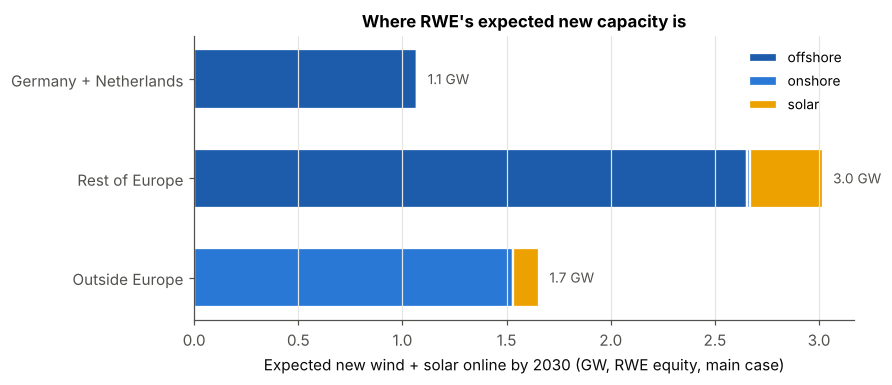

In [19]:
by = pipe.assign(region=np.where(pipe.de_nl, "Germany + Netherlands", np.where(pipe["Country/area"].isin(EUROPE), "Rest of Europe", "Outside Europe")))
comp = by.pivot_table(index="region", columns="grp", values="exp_gw", aggfunc="sum", fill_value=0)
comp = comp.reindex(["Germany + Netherlands", "Rest of Europe", "Outside Europe"]).fillna(0)
comp = comp[[c for c in ["offshore", "onshore", "solar"] if c in comp]]
print("expected new GW by 2030 (main case):")
print(comp.round(2).assign(total=comp.sum(axis=1)).to_string())
undated_gw = cand.loc[cand["Start year"].isna() & ~cand.Status.eq("construction") & ~off_mask, "gw"].sum()
print(f"undated onshore/solar left out of the main case: {undated_gw:.1f} GW")

fig, ax = plt.subplots(figsize=(8.2, 3.6))
left = np.zeros(len(comp))
for t in comp.columns:
    ax.barh(comp.index[::-1], comp[t][::-1], left=left[::-1], color=FUEL_COL[t], height=0.6, label=t,
            edgecolor="white", linewidth=1.5)
    left = left + comp[t].to_numpy()
for yi, v in enumerate(comp.sum(axis=1)[::-1]):
    ax.text(v + 0.05, yi, f"{v:.1f} GW", va="center", fontsize=9, color=C["ink2"])
ax.set(xlabel="Expected new wind + solar online by 2030 (GW, RWE equity, main case)",
       title="Where RWE's expected new capacity is")
ax.legend(fontsize=9)
ax.grid(axis="y", visible=False)
plt.tight_layout()
savefig(fig, "r5_pipeline_composition")
plt.show()

## 2.6 The metric, expected value, two perimeters and two bases

In [20]:
pipe_cf = np.average(pipe.grp.map(CF_MODE), weights=pipe.exp_gw)
adj = np.where(pipe.grp.ne("offshore"), 1 / COVERAGE, 1.0)   # offshore checked project by project -> no coverage gap


def exp_twh(mask=None, basis="GEM", p_col="p_main"):
    d = pipe if mask is None else pipe[mask]
    a = adj[d.index] if basis == "adjusted" else 1.0
    return float((d[p_col] * d.gw * a * d.grp.map(CF_MODE)).sum() * H_YEAR)


coal_twh_denl = COAL_TWH                     # all of RWE's coal is in DE + NL
metric = pd.DataFrame({
    "GEM-visible": {"Portfolio (worldwide pipeline)": exp_twh() / COAL_TWH,
                    "Germany + Netherlands only": exp_twh(pipe.de_nl) / coal_twh_denl},
    "coverage-adjusted": {"Portfolio (worldwide pipeline)": exp_twh(basis="adjusted") / COAL_TWH,
                          "Germany + Netherlands only": exp_twh(pipe.de_nl, basis="adjusted") / coal_twh_denl},
})
print(f"coal output to replace: {COAL_TWH:.1f} TWh/yr | expected new output (GEM basis): {exp_twh():.1f} TWh/yr")
metric.round(2)

coal output to replace: 32.1 TWh/yr | expected new output (GEM basis): 16.5 TWh/yr


,GEM-visible,coverage-adjusted
Portfolio (worldwide pipeline),0.52,0.59
Germany + Netherlands only,0.11,0.11


Two readings of the same ratio. As a **portfolio** metric (does RWE replace the output and margin it loses?), the worldwide pipeline counts. As a **coal-exit** metric (is the lost lignite output replaced where it is produced?), only Germany and the Netherlands count, and there RWE's own expected new output covers only about 12% of its coal output. That is not a failure of the exit (which is legally fixed), it means that the German replacement has to come mostly from other producers and from imports: the security-of-supply question is a system question (Part 3.3).

### Bridge: from the earlier estimate (0.98) to the current one, step by step
The headline moved a lot since Lab 5 (1.10) and our previous version (0.98). Every step below is a documented data or method correction, applied one at a time in this order, in expected value (the Monte Carlo medians are in the last rows). It shows where the change comes from.

In [21]:
raw = rwe[rwe.Type.isin(RE) & rwe.Status.isin(PIPE_STATUS) & ~(rwe["Start year"] > TARGET)].copy()
raw["gw"] = raw.mw_eq / 1000
raw_cf = raw.grp.map(CF_MODE)
P_PRE_OLD, P_ANN_OLD = 0.54, 0.34      # previous version: RWE-specific rates (per unit 0.67 x 0.80; MW 0.42 x 0.80)
is_off_raw = raw.grp.eq("offshore")
undated_raw = raw["Start year"].isna() & ~raw.Status.eq("construction")


def raw_twh(p):
    return float((p * raw.gw * raw_cf).sum() * H_YEAR)


p_old = np.select([raw.Status.eq("construction"), raw.Status.eq("pre-construction"), raw.Status.eq("announced") & ~is_off_raw],
                  [P_CON, P_PRE_OLD, P_ANN_OLD], 0.0)
base_sec = raw.grp.map(BUILD_RATE) * ON_TIME
p_sec = np.select([raw.Status.eq("construction"), raw.Status.eq("pre-construction"), raw.Status.eq("announced") & ~is_off_raw],
                  [P_CON, base_sec, 0.5 * base_sec], 0.0)
p_sec_dated = np.where(undated_raw, 0.0, p_sec)
coal_twh_old = coal_gw_main * CF_MODE["coal"] * H_YEAR
coal_twh_noeems_old = coal_gw_noeems * CF_MODE["coal"] * H_YEAR
bridge = pd.DataFrame([
    ("Lab 5 logic, no Eemshaven (Lab 5 Monte Carlo median: 1.10)", raw_twh(p_old) / coal_twh_noeems_old),
    ("+ Eemshaven added to the coal (previous version, MC median 0.98)", raw_twh(p_old) / coal_twh_old),
    ("+ coal capacity factor calibrated on reported emissions (0.50 -> 0.50 x B)", raw_twh(p_old) / COAL_TWH),
    ("+ sector build rates instead of RWE-specific rates", raw_twh(p_sec) / COAL_TWH),
    ("+ undated projects excluded", raw_twh(p_sec_dated) / COAL_TWH),
    ("+ offshore projects from public evidence (= current main case)", exp_twh() / COAL_TWH),
], columns=["step", "expected ratio"])
bridge["change"] = bridge["expected ratio"].diff()
bridge.round(2)

,step,expected ratio,change
0,"Lab 5 logic, no Eemshaven (Lab 5 Monte Carlo m...",1.19,NaN
1,+ Eemshaven added to the coal (previous versio...,1.01,-0.18
2,+ coal capacity factor calibrated on reported ...,1.09,0.08
3,+ sector build rates instead of RWE-specific r...,0.52,-0.57
4,+ undated projects excluded,0.30,-0.22
5,+ offshore projects from public evidence (= cu...,0.52,0.22


Reading the bridge: the calibration *raises* the ratio (less coal output to replace), while the move to sector build rates and especially the exclusion of undated projects *lower* it. Excluding undated projects is a choice (we only count what can be identified), so the current main case is a conservative lower bound; the undated projects come back in the *Full delivery* scenario and in the sensitivities.

## 2.7 Three scenarios with uncertainty (Monte Carlo, 5,000 draws)

| Scenario | Definition |
|---|---|
| **Track record** | RWE keeps adding wind + solar like in 2016-2025 (bootstrap of the 10 observed yearly additions, on the same basis as the pipeline) |
| **Current plan** | each project drawn with its main-case probability; the sector build rates and the evidence-based offshore probabilities are themselves uncertain (Beta, sd 0.10) |
| **Full delivery** | every project with a public or planned start ≤ 2030 is built (only timing risk), plus undated onshore/solar at 0.8 |

These are delivery hypotheses of our own; they are not IEA scenarios (the IEA benchmark is in 2.9).

**Correlation.** Projects are not independent: offshore projects share supply chains, auction rounds and interest rates. We draw each project's outcome through a Gaussian copula with a common shock per technology group (ρ = 0.5 for offshore, ρ = 0.3 for onshore/solar). This widens the intervals compared with independent draws, which our back-test (2.11) suggests is needed.

Capacity factors are drawn from the triangular ranges; the coal CF is scaled by the calibration factor B.

In [22]:
gw = pipe.gw.to_numpy()
grp_arr = pipe.grp.to_numpy()
is_off = grp_arr == "offshore"
RHO = {"offshore": 0.5, "rest": 0.3}


def beta_draw(mean, sd, size, g):
    mean = np.clip(mean, 1e-3, 1 - 1e-3)
    sd = np.minimum(sd, 0.95 * np.sqrt(mean * (1 - mean)))
    k = mean * (1 - mean) / sd ** 2 - 1
    return g.beta(mean * k, (1 - mean) * k, size)


rng = np.random.default_rng(SEED)
Z_off, Z_rest = rng.standard_normal(N), rng.standard_normal(N)
E = rng.standard_normal((N, len(gw)))


def uniforms(rho_off=RHO["offshore"], rho_rest=RHO["rest"]):
    lat = np.where(is_off, np.sqrt(rho_off) * Z_off[:, None] + np.sqrt(1 - rho_off) * E,
                   np.sqrt(rho_rest) * Z_rest[:, None] + np.sqrt(1 - rho_rest) * E)
    return stats.norm.cdf(lat)


U_corr, U_ind = uniforms(), uniforms(0.0, 0.0)
CF_DRAWS = {k: rng.triangular(*v, N) for k, v in CF_RANGE.items()}
unit_cf = np.column_stack([CF_DRAWS[g] for g in grp_arr])
coal_twh_draw = coal_gw_main * CF_DRAWS["coal"] * B_DRAW * H_YEAR

# probability matrix for the Current plan: uncertain sector build rates (shared) + uncertain evidence p (per project)
g2 = np.random.default_rng(SEED + 1)
br_draw = {t: beta_draw(BUILD_RATE[t], 0.10, N, g2) for t in ["onshore", "solar", "offshore"]}


def p_matrix(include_undated=False, vanguard=None, ontime=ON_TIME, off_cut=1.0, br_alt=None):
    P = np.zeros((N, len(gw)))
    for j, r in pipe.iterrows():
        if r.is_off_ev:
            pm = r.p_main if vanguard is None or not r["name"].startswith("Norfolk Vanguard") else vanguard
            pm = pm * (off_cut if r.p_main < 0.9 else 1.0)
            P[:, j] = pm if pm in (0.0,) else beta_draw(np.full(N, pm), 0.10 if pm < 0.9 else 0.03, N, g2)
        elif r.Status == "construction" and r.p_main > 0:
            P[:, j] = P_CON
        else:
            scale = br_draw[r.grp] * ontime / (BUILD_RATE[r.grp] * ON_TIME)    # shared uncertainty
            if br_alt is not None:
                scale = scale * br_alt[r.grp] / BUILD_RATE[r.grp]
            pm = r.p_main + (r.p_undated if include_undated else 0.0)
            P[:, j] = np.clip(pm * scale, 0, 1)
    return P


P_MAIN = p_matrix()
P_FULL = np.broadcast_to(pipe.p_full.to_numpy() + 0.8 * (pipe.p_undated.to_numpy() > 0), (N, len(gw)))


def run(P, U=U_corr, basis="GEM", mask=None):
    on = (U < P).astype(float)
    if mask is not None:
        on = on * mask[None, :]
    a = adj if basis == "adjusted" else np.ones(len(gw))
    return on @ (gw * a), (on * unit_cf) @ (gw * a) * H_YEAR


boot_idx = np.random.default_rng(SEED + 2).integers(0, 10, size=(N, TARGET - NOW))
last10 = hist.additions_GW.tail(10).to_numpy()
pipe_cf_draw = (unit_cf * pipe.exp_gw.to_numpy()).sum(axis=1) / pipe.exp_gw.sum()

SCEN = {}
for basis in ["GEM", "adjusted"]:
    tr_gw = last10[boot_idx].sum(axis=1) / (COVERAGE if basis == "adjusted" else 1.0)
    SCEN[("Track record", basis)] = (tr_gw, tr_gw * pipe_cf_draw * H_YEAR)
    SCEN[("Current plan", basis)] = run(P_MAIN, basis=basis)
    SCEN[("Full delivery", basis)] = run(P_FULL, basis=basis)

res = []
for (name, basis), (ngw, ntwh) in SCEN.items():
    ratio = ntwh / coal_twh_draw
    res.append({"scenario": name, "basis": basis, "new_GW_median": np.median(ngw),
                "new_GW_p05": np.percentile(ngw, 5), "new_GW_p95": np.percentile(ngw, 95),
                "ratio_median": np.median(ratio), "ratio_p05": np.percentile(ratio, 5), "ratio_p95": np.percentile(ratio, 95),
                "P(ratio>=1)": (ratio >= 1).mean(), "implied_pace_GW_yr": np.median(ngw) / (TARGET - NOW)})
scen = pd.DataFrame(res).set_index(["scenario", "basis"]).sort_index(level=1)
RATIO_DRAWS = {k: v[1] / coal_twh_draw for k, v in SCEN.items()}
NEWGW_DRAWS = {k: v[0] for k, v in SCEN.items()}
scen.round(2)

,,new_GW_median,new_GW_p05,new_GW_p95,ratio_median,ratio_p05,ratio_p95,P(ratio>=1),implied_pace_GW_yr
scenario,basis,,,,,,,,
Current plan,GEM,5.76,3.55,7.86,0.51,0.31,0.72,0.00,1.15
Full delivery,GEM,12.21,8.49,13.81,1.02,0.70,1.32,0.54,2.44
Track record,GEM,3.84,2.25,5.87,0.34,0.19,0.54,0.00,0.77
Current plan,adjusted,6.82,3.94,9.96,0.57,0.34,0.84,0.01,1.36
Full delivery,adjusted,15.47,10.48,17.64,1.22,0.84,1.60,0.83,3.09
Track record,adjusted,5.95,3.49,9.10,0.52,0.30,0.84,0.01,1.19


Probabilities in the text are rounded to the nearest 0.05 and translated into IPCC likelihood terms: the exact second decimal depends on assumptions (sd of the Beta, triangular bounds, ρ) that are chosen, not estimated.

In [23]:
def ipcc(p):
    return ("virtually certain" if p >= 0.99 else "very likely" if p >= 0.9 else "likely" if p >= 0.66 else
            "about as likely as not" if p >= 0.33 else "unlikely" if p >= 0.1 else "very unlikely" if p >= 0.01
            else "exceptionally unlikely")


def r05(p):
    return round(p * 20) / 20


summary_txt = scen.reset_index().assign(
    P_rounded=lambda d: d["P(ratio>=1)"].map(r05), likelihood=lambda d: d["P(ratio>=1)"].map(ipcc))
summary_txt[["scenario", "basis", "ratio_median", "ratio_p05", "ratio_p95", "P_rounded", "likelihood"]].round(2)

,scenario,basis,ratio_median,ratio_p05,ratio_p95,P_rounded,likelihood
0,Current plan,GEM,0.51,0.31,0.72,0.00,exceptionally unlikely
1,Full delivery,GEM,1.02,0.70,1.32,0.55,about as likely as not
2,Track record,GEM,0.34,0.19,0.54,0.00,exceptionally unlikely
3,Current plan,adjusted,0.57,0.34,0.84,0.00,exceptionally unlikely
4,Full delivery,adjusted,1.22,0.84,1.60,0.85,likely
5,Track record,adjusted,0.52,0.30,0.84,0.00,very unlikely


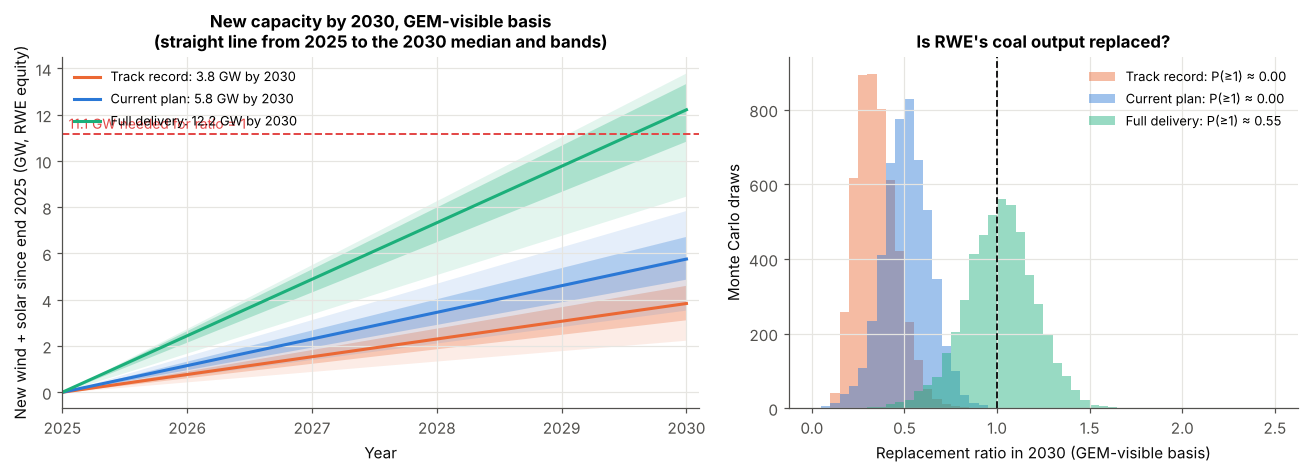

In [24]:
need_new_gw = COAL_TWH / (pipe_cf * H_YEAR)             # real GW of new wind+solar for ratio = 1
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
fut = np.arange(NOW, TARGET + 1)
w = (fut - NOW) / (TARGET - NOW)
for name in ["Track record", "Current plan", "Full delivery"]:
    d = NEWGW_DRAWS[(name, "GEM")]
    q05, q25, q50, q75, q95 = np.percentile(d, [5, 25, 50, 75, 95])
    col = SCEN_COL[name]
    ax.fill_between(fut, q05 * w, q95 * w, color=col, alpha=0.12, lw=0)
    ax.fill_between(fut, q25 * w, q75 * w, color=col, alpha=0.28, lw=0)
    ax.plot(fut, q50 * w, color=col, lw=2, label=f"{name}: {q50:.1f} GW by 2030")
ax.axhline(need_new_gw, color=C["red"], ls="--", lw=1.3)
ax.text(NOW + 0.05, need_new_gw + 0.25, f"{need_new_gw:.1f} GW needed for ratio = 1", fontsize=9, color=C["red"])
ax.set(xlabel="Year", ylabel="New wind + solar since end 2025 (GW, RWE equity)", xlim=(NOW, TARGET + 0.1),
       title="New capacity by 2030, GEM-visible basis\n(straight line from 2025 to the 2030 median and bands)")
ax.legend(loc="upper left", fontsize=8.5)
ax = axes[1]
bins = np.linspace(0, 2.5, 51)
for name in ["Track record", "Current plan", "Full delivery"]:
    r_ = RATIO_DRAWS[(name, "GEM")]
    ax.hist(r_, bins=bins, color=SCEN_COL[name], alpha=0.45, label=f"{name}: P(≥1) ≈ {r05((r_ >= 1).mean()):.2f}")
ax.axvline(1, color=C["ink"], ls="--", lw=1.2)
ax.set(xlabel="Replacement ratio in 2030 (GEM-visible basis)", ylabel="Monte Carlo draws", title="Is RWE's coal output replaced?")
ax.legend(fontsize=8.5)
plt.tight_layout()
savefig(fig, "r3_scenarios")
plt.show()

## 2.8 Criteria C1 and C2

**C2 on a homogeneous basis.** The need is physical (real GW). It is compared with RWE's past pace on three bases: what GEM sees, the same corrected for GEM's 64% coverage, and what RWE itself reports (≈ 2.0 GW commissioned in 2024 and 2.8 GW in 2025 across all technologies, batteries included, so an upper bound for wind + solar). We also look at the timing: the lignite exits on 31 March 2030, so a strict reading counts only capacity online before then (4.25 years of building from January 2026, projects with COD ≤ 2029).

In [25]:
req = {"end of 2030 (5 years)": need_new_gw / 5, "31 March 2030 (4.25 years)": need_new_gw / 4.25}
hist_pace = pd.DataFrame({
    "best 3-year average": [pace.loc["best 3-year average", "GEM-visible"], pace.loc["best 3-year average", "coverage-adjusted"], (2.0 + 2.8) / 2],
    "last 10 years": [pace.loc["last 10 years", "GEM-visible"], pace.loc["last 10 years", "coverage-adjusted"], np.nan],
}, index=["GEM-visible", "coverage-adjusted", "RWE-reported (2024-25, all technologies)"])
for k, v in req.items():
    hist_pace[f"required / best ({k})"] = v / hist_pace["best 3-year average"]
# upper bound on the acquisition effect: drop every US asset commissioned before 2023 (acquired with E.ON's
# portfolio in 2019 or Con Edison Clean Energy in 2023, or built by RWE itself)
ex_us = built[~(built["Country/area"].eq("United States") & (built["Start year"] < 2023))]
add_ex = pd.Series([ex_us.loc[ex_us["Start year"] == y, "mw_eq"].sum() / 1000 for y in years], index=years)
hist_pace.loc["coverage-adjusted, excl. pre-2023 US assets", ["best 3-year average", "last 10 years"]] = [
    add_ex.rolling(3).mean().max() / COVERAGE, add_ex.tail(10).mean() / COVERAGE]
for k, v in req.items():
    hist_pace[f"required / best ({k})"] = v / hist_pace["best 3-year average"]
hist_pace["C2 pass (end-2030 timing)"] = hist_pace["required / best (end of 2030 (5 years))"] <= 1
hist_pace["role"] = ["lower bound", "DECISIVE", "upper bound (incl. batteries)", "acquisition check"]
print({k: round(v, 2) for k, v in req.items()}, "GW/yr required")
cp_gem = scen.loc[("Current plan", "GEM")]
print(f"H0 in its V0 wording: pace implied by the Current plan pipeline {cp_gem.implied_pace_GW_yr:.2f} GW/yr "
      f"vs GEM-visible history {pace.loc['last 10 years', 'GEM-visible']:.2f}-{pace.loc['best 3-year average', 'GEM-visible']:.2f} GW/yr "
      f"-> {'consistent' if cp_gem.implied_pace_GW_yr <= pace.loc['best 3-year average', 'GEM-visible'] else 'faster than history'}")
hist_pace.round(2)

{'end of 2030 (5 years)': np.float64(2.23), '31 March 2030 (4.25 years)': np.float64(2.62)} GW/yr required
H0 in its V0 wording: pace implied by the Current plan pipeline 1.15 GW/yr vs GEM-visible history 0.78-1.26 GW/yr -> consistent


,best 3-year average,last 10 years,required / best (end of 2030 (5 years)),required / best (31 March 2030 (4.25 years)),C2 pass (end-2030 timing),role
GEM-visible,1.26,0.78,1.78,2.09,False,lower bound
coverage-adjusted,1.95,1.22,1.14,1.35,False,DECISIVE
"RWE-reported (2024-25, all technologies)",2.40,NaN,0.93,1.09,True,upper bound (incl. batteries)
"coverage-adjusted, excl. pre-2023 US assets",1.17,0.76,1.91,2.24,False,acquisition check


**Confronting the pipeline with RWE's published strategy.** In March 2025 RWE cut its 2025-2030 net investment plan by €10 bn to €35 bn, raised its hurdle rate above 8.5% and paused its US offshore wind activities (RWE, 20 Mar 2025; Offshore Magazine, 29 Apr 2025). In March 2026 it announced a portfolio of about 65 GW by 2031, +25 GW, of which +6 GW of flexible generation in Germany (gas and batteries), +5 GW offshore (net), +5 GW onshore wind and solar in Europe and Australia, and +9 GW in the US (13 → 22 GW, including batteries) (RWE, 12 Mar 2026). Excluding the German flexible capacity, that is about 19 GW in six years, ≈ 3.2 GW/yr, including an unknown share of batteries.

In [26]:
RWE_GUIDANCE_GW_2026_31 = 5 + 5 + 9                       # offshore + onshore/solar EU&AUS + US (incl. batteries)
guid_pace = RWE_GUIDANCE_GW_2026_31 / 6
guid_2030 = guid_pace * (TARGET - NOW)
guid_ratio = guid_2030 * pipe_cf * H_YEAR / COAL_TWH
cmp_pace = pd.Series({
    "required for ratio = 1 (end 2030)": req["end of 2030 (5 years)"],
    "RWE guidance 2026-31, excl. German flex (incl. batteries)": guid_pace,
    "Current plan: dated + evidenced projects (GEM-visible)": scen.loc[("Current plan", "GEM"), "implied_pace_GW_yr"],
    "Track record (GEM-visible, last 10 years)": pace.loc["last 10 years", "GEM-visible"],
    "Track record (coverage-adjusted, best 3 years)": pace.loc["best 3-year average", "coverage-adjusted"],
}, name="GW per year")
print(f"if RWE's guidance were all wind + solar and pro rata to 2030: {guid_2030:.1f} GW -> ratio {guid_ratio:.2f}")
cmp_pace.round(2)

if RWE's guidance were all wind + solar and pro rata to 2030: 15.8 GW -> ratio 1.42


required for ratio = 1 (end 2030)                           2.23
RWE guidance 2026-31, excl. German flex (incl. batteries)   3.17
Current plan: dated + evidenced projects (GEM-visible)      1.15
Track record (GEM-visible, last 10 years)                   0.78
Track record (coverage-adjusted, best 3 years)              1.95
Name: GW per year, dtype: float64

RWE's **guidance** (≈ 3.2 GW/yr, batteries included) is above the pace needed (≈ 2.1 GW/yr), and RWE's **recent reported commissioning** is close to the need. But the projects **identifiable today** (dated in GEM, or documented offshore) only support ≈ 1.2 GW/yr. The difference is the part of RWE's plan that is not yet attached to named, dated projects, and that is where the credibility question sits.

In [27]:
exit_mask = pipe.in_exit.to_numpy().astype(float)
ngw_exit, ntwh_exit = run(P_MAIN, mask=exit_mask)
r_exit = ntwh_exit / coal_twh_draw
c1 = pd.DataFrame({
    "P(ratio>=1)": [scen.loc[("Current plan", "GEM"), "P(ratio>=1)"], scen.loc[("Current plan", "adjusted"), "P(ratio>=1)"],
                    (r_exit >= 1).mean()],
    "median ratio": [scen.loc[("Current plan", "GEM"), "ratio_median"], scen.loc[("Current plan", "adjusted"), "ratio_median"],
                     np.median(r_exit)],
}, index=["Current plan, GEM-visible, end 2030", "Current plan, coverage-adjusted, end 2030",
          "Current plan, GEM-visible, online before 31 Mar 2030"])
for basis, lab in [("GEM", "Full delivery, GEM-visible, end 2030"), ("adjusted", "Full delivery, coverage-adjusted, end 2030")]:
    c1.loc[lab] = [scen.loc[("Full delivery", basis), "P(ratio>=1)"], scen.loc[("Full delivery", basis), "ratio_median"]]
c1["rounded"] = c1["P(ratio>=1)"].map(r05)
c1["likelihood"] = c1["P(ratio>=1)"].map(ipcc)
c1["C1 pass (P >= 0.66)"] = c1["P(ratio>=1)"] >= 0.66
c1.round(2)

,P(ratio>=1),median ratio,rounded,likelihood,C1 pass (P >= 0.66)
"Current plan, GEM-visible, end 2030",0.00,0.51,0.00,exceptionally unlikely,False
"Current plan, coverage-adjusted, end 2030",0.01,0.57,0.00,exceptionally unlikely,False
"Current plan, GEM-visible, online before 31 Mar 2030",0.00,0.47,0.00,exceptionally unlikely,False
"Full delivery, GEM-visible, end 2030",0.54,1.02,0.55,about as likely as not,False
"Full delivery, coverage-adjusted, end 2030",0.83,1.22,0.85,likely,True


## 2.9 IEA benchmark, pro rata
We test RWE's 2030 wind + solar capacity against IEA trajectories applied **pro rata to RWE's 2022 capacity**, i.e. we ask whether RWE grows its renewable fleet as fast as the world does in each IEA case:
* **IEA Renewables 2025, main case**: 9,530 GW of renewable capacity in 2030 (IEA, *Renewables 2025*);
* **IEA Renewables 2025, accelerated case**: about 10,400 GW;
* **Tripling** (COP28 pledge, consistent with the IEA Net Zero pathway): about 11,500 GW according to the IEA.

The IEA puts the tripling target at ~11,500 GW, which implies a 2022 base of ~3,830 GW; the multipliers are therefore 2.49, 2.72 and 3.0. Two limits: these multipliers cover *all* renewables, including hydro that grows slowly, so they understate the growth expected from wind and solar alone; and they are global, driven by Chinese solar, while a PACTA-style test would use a regional trajectory per technology. We could not source a European wind + solar trajectory in time, so this benchmark tests the *ambition* of RWE's plan in a rough way only.

**The target itself.** On coal, RWE's timeline (lignite out by 31 March 2030, Eemshaven off coal by 2030) is aligned with the IEA Net Zero milestone of phasing out unabated coal in advanced economies by 2030. What is not aligned, on identifiable projects, is the replacement.

In [28]:
GLOBAL_2022 = 11_500 / 3
IEA_MULT = {"IEA main case (x2.49)": 9_530 / GLOBAL_2022, "IEA accelerated case (x2.72)": 10_400 / GLOBAL_2022,
            "Tripling / NZE (x3.0)": 3.0}
cap22 = hist.set_index("year").loc[2022, "capacity_GW"]
old = built.loc[(built["Start year"] <= TARGET - 25) & ~(built["Retired year"] <= NOW), "mw_eq"].sum() / 1000
iea_rows = []
for basis, k in [("GEM", 1.0), ("adjusted", 1 / COVERAGE)]:
    for name in ["Track record", "Current plan", "Full delivery"]:
        cap30 = (cap_now - old) * k + NEWGW_DRAWS[(name, basis)]
        row = {"basis": basis, "scenario": name, "RWE 2030 median (GW)": np.median(cap30)}
        for lab, m in IEA_MULT.items():
            row[f"P(>= {lab})"] = (cap30 >= cap22 * k * m).mean()
        iea_rows.append(row)
iea = pd.DataFrame(iea_rows).set_index(["basis", "scenario"])
print("benchmarks (GEM basis):", {lab: round(cap22 * m, 1) for lab, m in IEA_MULT.items()})
iea.round(2)

benchmarks (GEM basis): {'IEA main case (x2.49)': np.float64(26.4), 'IEA accelerated case (x2.72)': np.float64(28.8), 'Tripling / NZE (x3.0)': np.float64(31.8)}


RWE 2030 median (GW)  P(>= IEA main case (x2.49))  P(>= IEA accelerated case (x2.72))  P(>= Tripling / NZE (x3.0))
basis    scenario                                                                                                                         
GEM      Track record                  16.05                         0.00                                0.00                         0.00
         Current plan                  17.97                         0.00                                0.00                         0.00
         Full delivery                 24.43                         0.00                                0.00                         0.00
adjusted Track record                  24.89                         0.00                                0.00                         0.00
         Current plan                  25.77                         0.00                                0.00                         0.00
         Full delivery                 34.41                         0.00                                0.00                         0.00

## 2.10 Sensitivities (Current plan, GEM-visible basis)

In [29]:
sens_rows = []


def add_sens(label, ratio):
    sens_rows.append({"case": label, "ratio_median": float(np.median(ratio)), "P(ratio>=1)": float((ratio >= 1).mean())})


base_ratio = RATIO_DRAWS[("Current plan", "GEM")]
add_sens("Base case", base_ratio)
add_sens("Coverage-adjusted basis (onshore/solar ÷ 0.64)", RATIO_DRAWS[("Current plan", "adjusted")])
add_sens("Undated onshore/solar included", run(p_matrix(include_undated=True))[1] / coal_twh_draw)
add_sens("Norfolk Vanguard p = 0.3", run(p_matrix(vanguard=0.3))[1] / coal_twh_draw)
add_sens("Norfolk Vanguard p = 0.85", run(p_matrix(vanguard=0.85))[1] / coal_twh_draw)
add_sens("Only capacity online before 31 Mar 2030", r_exit)
add_sens("Germany + Netherlands pipeline only", run(P_MAIN, mask=pipe.de_nl.to_numpy().astype(float))[1] / coal_twh_draw)
add_sens("Slippage factor 0.6 instead of 0.8", run(p_matrix(ontime=0.6))[1] / coal_twh_draw)
_e = eu[eu.Type.isin(RE) & eu.grp.isin(["offshore", "onshore", "solar"])]
_eok = _e.Status.isin(["operating", "retired"]) & (_e["Start year"] >= 2015)
_eko = _e.Status.str.startswith(("cancelled", "shelved"))
BR_EUROPE = {t: _e.loc[_eok & _e.grp.eq(t), "Capacity (MW)"].sum() / _e.loc[(_eok | _eko) & _e.grp.eq(t), "Capacity (MW)"].sum()
             for t in ["offshore", "onshore", "solar"]}
print("Europe-only build rates:", {k: round(v, 2) for k, v in BR_EUROPE.items()})
add_sens("Europe-only build rates", run(p_matrix(br_alt=BR_EUROPE))[1] / coal_twh_draw)
add_sens("RWE's own per-unit build rate (0.67, optimistic)", run(p_matrix(br_alt={t: 0.67 for t in BUILD_RATE}))[1] / coal_twh_draw)
add_sens("B fixed at its point estimate", run(P_MAIN)[1] / (coal_gw_main * CF_DRAWS["coal"] * B * H_YEAR))
add_sens("Coal CF not calibrated (0.50 instead of 0.50 x B)", run(P_MAIN)[1] / (coal_gw_main * CF_DRAWS["coal"] * H_YEAR))
add_sens("Without Eemshaven (Lab 5 / biomass conversion)", run(P_MAIN)[1] / (coal_gw_noeems * CF_DRAWS["coal"] * B_DRAW * H_YEAR))
add_sens("GKM excluded (operational control)", run(P_MAIN)[1] / (coal_gw_nogkm * CF_DRAWS["coal"] * B_DRAW * H_YEAR))
add_sens("Independent projects (rho = 0)", run(P_MAIN, U=U_ind)[1] / coal_twh_draw)
gas_gw_now = op.loc[op.Type == "oil/gas", "mw_eq"].sum() / 1000
add_sens("Full fossil exit (coal + all gas)", run(P_MAIN)[1] / ((coal_gw_main * CF_DRAWS["coal"] + gas_gw_now * CF_DRAWS["gas"]) * B_DRAW * H_YEAR))
sens = pd.DataFrame(sens_rows).set_index("case")

# horizon 2035 (expected value): AR7 projects (DBS, Awel y Môr) and dated <= 2035 projects count
c35 = cand.copy()
p35 = np.where(c35.evidence.ne("") & c35.cod.le(TARGET), c35.p_main,
               np.where(c35.evidence.ne("") & c35.cod.between(TARGET + 1, 2035), 0.6, 0.0))   # AR7 CfD projects (DBS, Awel y Môr)
p35 = np.where(c35.evidence.eq("") & ~c35.grp.eq("offshore"),
               np.select([c35.Status.eq("construction"), c35["Start year"] <= 2035], [P_CON, c35.grp.map(BUILD_RATE) * ON_TIME], 0.0), p35)
twh35 = float((p35 * c35.gw * c35.grp.map(CF_MODE)).sum() * H_YEAR)
sens.loc["Horizon 2035 (expected value, AR7 projects included)"] = [twh35 / COAL_TWH, np.nan]
sens["P_rounded"] = sens["P(ratio>=1)"].map(lambda p: r05(p) if pd.notna(p) else np.nan)
sens.round(2)

Europe-only build rates: {'offshore': np.float64(0.13), 'onshore': np.float64(0.5), 'solar': np.float64(0.64)}


,ratio_median,P(ratio>=1),P_rounded
case,,,
Base case,0.51,0.00,0.00
Coverage-adjusted basis (onshore/solar ÷ 0.64),0.57,0.01,0.00
Undated onshore/solar included,0.61,0.01,0.00
Norfolk Vanguard p = 0.3,0.46,0.00,0.00
Norfolk Vanguard p = 0.85,0.55,0.00,0.00
Only capacity online before 31 Mar 2030,0.47,0.00,0.00
Germany + Netherlands pipeline only,0.11,0.00,0.00
Slippage factor 0.6 instead of 0.8,0.49,0.00,0.00
Europe-only build rates,0.49,0.00,0.00


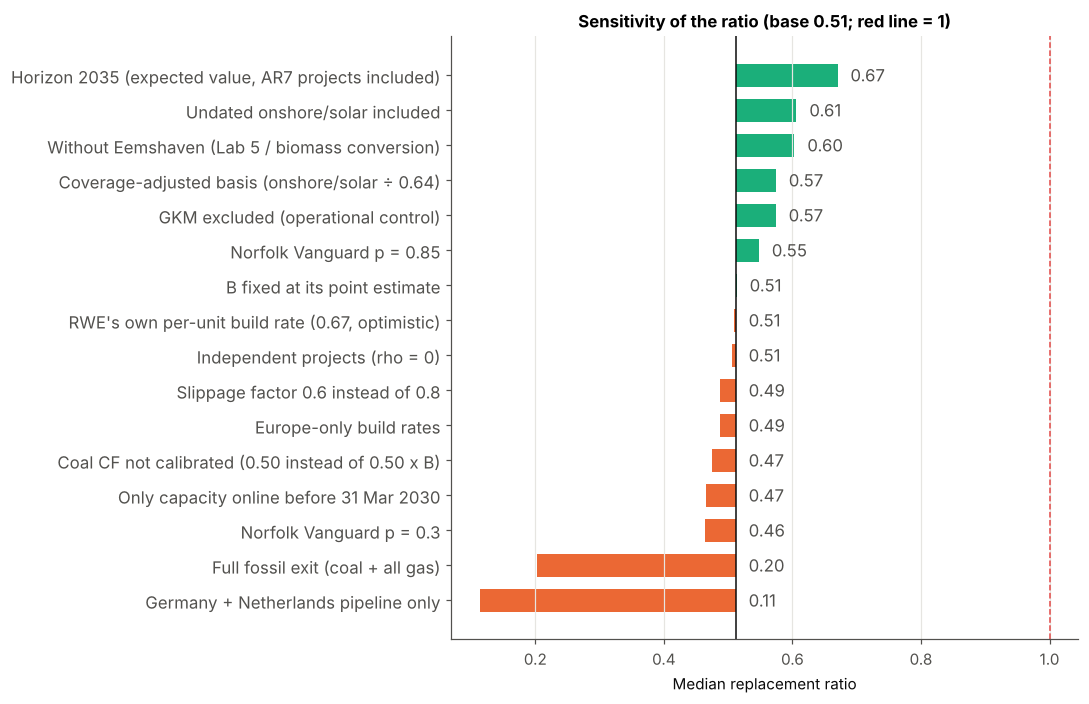

In [30]:
s = sens.drop(index="Base case").dropna(subset=["ratio_median"])
base_med = sens.loc["Base case", "ratio_median"]
s = s.assign(delta=s.ratio_median - base_med).sort_values("delta")
fig, ax = plt.subplots(figsize=(10, 6.5))
yy = np.arange(len(s))
ax.barh(yy, s.delta, left=base_med, color=[C["aqua"] if d > 0 else C["orange"] for d in s.delta], height=0.65)
ax.axvline(base_med, color=C["ink"], lw=1)
ax.axvline(1, color=C["red"], ls="--", lw=1)
ax.set_yticks(yy, s.index, fontsize=11)
for yi, (d, m) in enumerate(zip(s.delta, s.ratio_median)):
    ax.text(max(m, base_med) + 0.02, yi, f"{m:.2f}", va="center", fontsize=11, color=C["ink2"])
ax.set(xlabel="Median replacement ratio", title=f"Sensitivity of the ratio (base {base_med:.2f}; red line = 1)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
savefig(fig, "r4_tornado")
plt.show()

## 2.11 Back-test reminder (Lab 5) and what it says about our intervals
In Lab 5 we hid 2021-2025 and forecast them with trend models: the linear trend caught 1 of 5 held-out years in its 90% band, and a naive drift had the best interval score (Gneiting & Raftery, 2007). Below, the rolling version: even the best model covers only ~67% of outcomes three years ahead with a nominal 90% band. Our intervals from simple models are **too narrow**, which is one reason we added correlated project risk in 2.7 and why the 90% intervals of this notebook should be read as a lower bound on the true uncertainty.

In [31]:
def drift_forecast(train, h, level=0.90):
    y = train.to_numpy(float)
    d = np.diff(y)
    k = min(4, len(d))
    hh = np.arange(1, h + 1)
    mean = y[-1] + d[-k:].mean() * hh
    half = stats.t.ppf(0.5 + level / 2, df=len(d) - 1) * d.std(ddof=1) * np.sqrt(hh + hh ** 2 / k)
    return mean, mean - half, mean + half


def linear_forecast(train_years, train, h, level=0.90):
    x, y = train_years.to_numpy(float), train.to_numpy(float)
    X = np.column_stack([np.ones_like(x), x - x.mean()])
    XtX = np.linalg.inv(X.T @ X)
    b = XtX @ X.T @ y
    s_ = np.sqrt(((y - X @ b) ** 2).sum() / (len(y) - 2))
    fut_x = np.arange(x.max() + 1, x.max() + 1 + h)
    X0 = np.column_stack([np.ones(h), fut_x - x.mean()])
    mean = X0 @ b
    half = stats.t.ppf(0.5 + level / 2, len(y) - 2) * s_ * np.sqrt(1 + np.einsum("ij,jk,ik->i", X0, XtX, X0))
    return mean, mean - half, mean + half


rows = []
for i in range(10, len(hist)):
    tr = hist.iloc[:i]
    for m in ["linear", "drift"]:
        mean, lo, hi = (linear_forecast(tr.year, tr.capacity_GW, 3) if m == "linear" else drift_forecast(tr.capacity_GW, 3))
        for h in range(3):
            j = i + h
            if j < len(hist):
                yv = hist.capacity_GW.iloc[j]
                rows.append({"model": m, "h": h + 1, "inside": lo[h] <= yv <= hi[h]})
roll = pd.DataFrame(rows).pivot_table(index="model", columns="h", values="inside", aggfunc="mean")
roll.columns = [f"coverage h={c} (nominal 0.90)" for c in roll.columns]
roll.round(2)

,coverage h=1 (nominal 0.90),coverage h=2 (nominal 0.90),coverage h=3 (nominal 0.90)
model,,,
drift,0.91,0.80,0.67
linear,0.73,0.60,0.56


---
# Part 3. Extensions

## 3.1 Emission intensity vs RWE's SBTi target
RWE's SBTi-validated target: **−71.1% Scope 1+2 GHG emissions per MWh by 2030 vs 2022** (RWE, 16 Jan 2025). We anchor the base year on **the intensity RWE itself publishes for this metric**: 0.55 tCO₂e/MWh in 2022 (Scope 1+2; 0.48 in 2023 and 0.43 in 2025, RWE Sustainability Performance Report 2023 and Factbook 2026). The 2030 target is therefore 0.55 × (1 − 0.711) ≈ 0.159 tCO₂e/MWh. (For comparison, power-plant CO₂ only gives 83.0 Mt / 156.8 TWh = 0.53.) RWE's 2022 generation by source: lignite 50.0, gas 51.7, renewables 35.5, nuclear 11.9, hard coal 7.2 TWh.

2030 projection:
* emissions = B × modelled emissions of the fossil fleet still running (coal by case, gas fleet + new H₂-ready gas in GEM);
* generation = B × modelled fossil output + output of today's wind + solar fleet calibrated on RWE's reported 2022 wind + solar output (29.2 TWh: onshore 17.6, offshore 10.2, solar 1.4) + hydro and biomass held at their 2022 level (6.2 TWh) + new wind + solar from the Monte Carlo.

Calibrating the existing fleet on reported output replaces the ÷ 0.64 coverage factor here, so the coverage question is handled by one consistent calibration rather than two different factors.

In [32]:
INT_2022 = 0.55                      # RWE-published Scope 1+2 intensity, 2022 (tCO2e/MWh)
INT_PUBLISHED = pd.Series({2022: 0.55, 2023: 0.48, 2025: 0.43})
INT_TARGET = INT_2022 * (1 - 0.711)
gas = op[op.Type == "oil/gas"]
GAS_GW_NOW = gas.mw_eq.sum() / 1000
gas_pipe = rwe[(rwe.Type == "oil/gas") & rwe.Status.isin(["pre-construction", "construction"]) & ~(rwe["Start year"] > TARGET)]
NEW_GAS_GW = gas_pipe.mw_eq.sum() / 1000
re_now_cf = np.average(built.grp.map(CF_MODE).fillna(0.26), weights=built.mw_eq)
K_RE = 29.2 / (hist.set_index("year").loc[2022, "capacity_GW"] * re_now_cf * H_YEAR)   # calibrates GEM fleet on reported output
OTHER_RE_TWH = 1.6 + 4.6
existing_re_2030 = (cap_now - old) * re_now_cf * H_YEAR * K_RE
print(f"2022 published intensity {INT_2022:.3f} t/MWh -> 2030 target {INT_TARGET:.3f} t/MWh")
# validation: our model in 2023 and 2025 vs RWE's published intensity
for yv in [2023, 2025]:
    mt_m, twh_m = modelled(yv)
    re_y = hist.set_index("year").loc[yv, "capacity_GW"] * re_now_cf * H_YEAR * K_RE
    print(f"model check {yv}: intensity {B * mt_m / (B * twh_m + re_y + OTHER_RE_TWH):.2f} vs published {INT_PUBLISHED[yv]:.2f} tCO2e/MWh")
print(f"K_RE = {K_RE:.2f} (reported 2022 wind+solar output / GEM-modelled) | gas {GAS_GW_NOW:.1f} GW + new {NEW_GAS_GW:.2f} GW")

RESERVE_CF = 0.10      # a unit in the federal reserve only runs when called by the grid operator


def fossil_2030(case="contract", gas_cf=0.45):
    c = coal.copy()
    if case == "contract":
        c = c[c.close_contract > TARGET]
        cf = np.full(len(c), CF_MODE["coal"])
    else:
        c = c[c.close_reserve > TARGET]
        cf = np.where(c.is_reserve_unit, RESERVE_CF if case == "reserve" else CF_MODE["coal"], CF_MODE["coal"])
    coal_twh = float((c.coal_mw / 1000 * cf).sum() * H_YEAR)
    coal_mt = float((c.coal_mw / 1000 * cf * c.coal_kind.map(EF)).sum() * H_YEAR)
    gas_twh = (GAS_GW_NOW + NEW_GAS_GW) * gas_cf * H_YEAR
    return B_DRAW * (coal_twh + gas_twh), B_DRAW * (coal_mt + gas_twh * EF["gas"])   # arrays (B uncertain)


gap_rows = []
for name in ["Track record", "Current plan", "Full delivery"]:
    new_twh = SCEN[(name, "GEM")][1]
    for case, lab in [("contract", "contract 2030"), ("reserve", "reserve to 2033 (dispatched at 10%)"),
                      ("reserve_worst", "reserve to 2033 (worst case, runs like today)")]:
        f_twh, f_mt = fossil_2030(case)
        inten = f_mt / (f_twh + existing_re_2030 + OTHER_RE_TWH + new_twh)
        gap_rows.append({"scenario": name, "coal case": lab, "emissions_Mt": float(np.median(f_mt)),
                         "generation_TWh": float(np.median(f_twh + existing_re_2030 + OTHER_RE_TWH + new_twh)),
                         "intensity_t_MWh": float(np.median(inten)), "intensity_p05": float(np.percentile(inten, 5)),
                         "intensity_p95": float(np.percentile(inten, 95)), "P(on track)": float((inten <= INT_TARGET).mean()),
                         "target": INT_TARGET})
gap = pd.DataFrame(gap_rows)
gap["status"] = np.where(gap["P(on track)"] >= 0.66, "on track (likely)",
                         np.where(gap["P(on track)"] >= 0.33, "borderline", "off track"))
gcf = {}
for gc in [0.30, 0.45, 0.55]:
    f_twh, f_mt = fossil_2030("contract", gc)
    gcf[f"gas CF {gc}"] = float(np.median(f_mt / (f_twh + existing_re_2030 + OTHER_RE_TWH + SCEN[("Current plan", "GEM")][1])))
print("Current plan, contract case, intensity vs gas utilisation:", {k: round(v, 3) for k, v in gcf.items()})
gap.round(3)

2022 published intensity 0.550 t/MWh -> 2030 target 0.159 t/MWh
model check 2023: intensity 0.52 vs published 0.48 tCO2e/MWh
model check 2025: intensity 0.44 vs published 0.43 tCO2e/MWh
K_RE = 1.18 (reported 2022 wind+solar output / GEM-modelled) | gas 15.7 GW + new 1.78 GW
Current plan, contract case, intensity vs gas utilisation: {'gas CF 0.3': 0.183, 'gas CF 0.45': 0.22, 'gas CF 0.55': 0.239}


,scenario,coal case,emissions_Mt,generation_TWh,intensity_t_MWh,intensity_p05,intensity_p95,P(on track),target,status
0,Track record,contract 2030,26.95,116.65,0.23,0.22,0.24,0.00,0.16,off track
1,Track record,reserve to 2033 (dispatched at 10%),29.95,119.25,0.25,0.24,0.27,0.00,0.16,off track
2,Track record,"reserve to 2033 (worst case, runs like today)",41.93,129.69,0.32,0.30,0.34,0.00,0.16,off track
3,Current plan,contract 2030,26.95,122.25,0.22,0.21,0.23,0.00,0.16,off track
4,Current plan,reserve to 2033 (dispatched at 10%),29.95,124.84,0.24,0.23,0.26,0.00,0.16,off track
5,Current plan,"reserve to 2033 (worst case, runs like today)",41.93,135.26,0.31,0.29,0.33,0.00,0.16,off track
6,Full delivery,contract 2030,26.95,139.02,0.19,0.18,0.21,0.00,0.16,off track
7,Full delivery,reserve to 2033 (dispatched at 10%),29.95,141.62,0.21,0.20,0.23,0.00,0.16,off track
8,Full delivery,"reserve to 2033 (worst case, runs like today)",41.93,151.98,0.28,0.26,0.30,0.00,0.16,off track


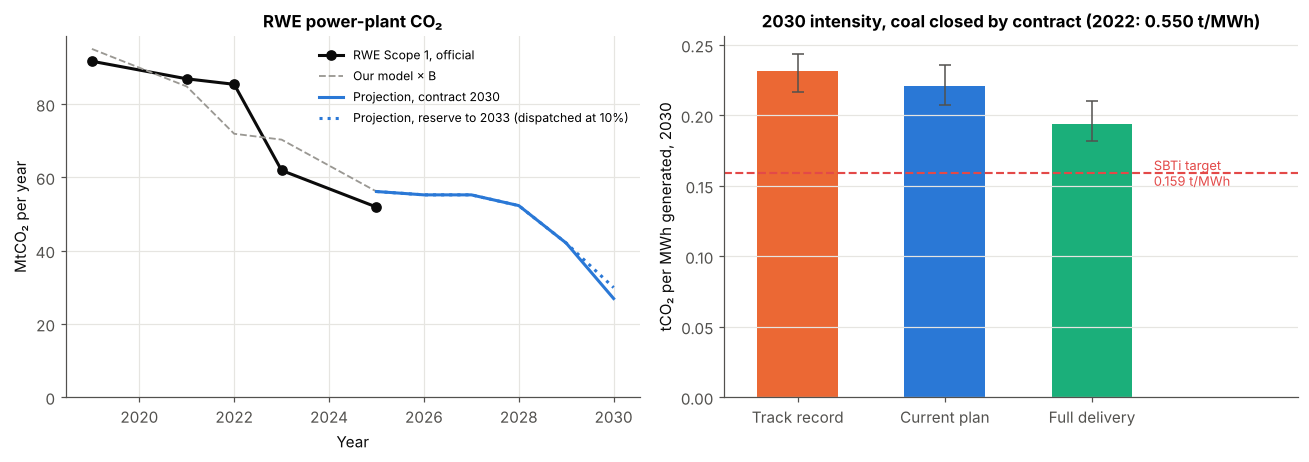

In [33]:
yrs_p = np.arange(NOW + 1, TARGET + 1)
path_rows = []
for name in ["Track record", "Current plan", "Full delivery"]:
    for case, lab in [("contract", "contract 2030"), ("reserve", "reserve to 2033 (dispatched at 10%)")]:
        for y in yrs_p:
            c = coal[(coal.close_contract if case == "contract" else coal.close_reserve) > y]
            cf = np.where((case == "reserve") & c.is_reserve_unit & (y >= TARGET), RESERVE_CF, CF_MODE["coal"])
            coal_mt = float((c.coal_mw / 1000 * cf * c.coal_kind.map(EF)).sum() * H_YEAR)
            gas_gw_y = GAS_GW_NOW + (NEW_GAS_GW if y >= TARGET else 0)
            gas_mt = gas_gw_y * (0.40 + 0.05 * (y >= TARGET)) * H_YEAR * EF["gas"]
            path_rows.append({"scenario": name, "case": lab, "year": int(y), "Mt": B * (coal_mt + gas_mt)})
em_paths = pd.DataFrame(path_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
ax.plot(REPORTED.index, REPORTED.values, color=C["ink"], marker="o", lw=2, label="RWE Scope 1, official")
ax.plot(calib.index, calib.fitted_Mt, color=C["muted"], ls="--", lw=1.2, label="Our model × B")
for lab, ls in [("contract 2030", "-"), ("reserve to 2033 (dispatched at 10%)", ":")]:
    d = em_paths[(em_paths.scenario == "Current plan") & (em_paths.case == lab)]
    ax.plot(np.r_[NOW, d.year], np.r_[calib.fitted_Mt.iloc[-1], d.Mt], color=C["blue"], ls=ls, lw=2, label=f"Projection, {lab}")
ax.set(xlabel="Year", ylabel="MtCO₂ per year", ylim=(0, None), title="RWE power-plant CO₂")
ax.legend(fontsize=8)
ax = axes[1]
gg = gap[gap["coal case"] == "contract 2030"].set_index("scenario")
xx = np.arange(len(gg))
ax.bar(xx, gg.intensity_t_MWh, color=[SCEN_COL[s_] for s_ in gg.index], width=0.55)
ax.errorbar(xx, gg.intensity_t_MWh, yerr=[gg.intensity_t_MWh - gg.intensity_p05, gg.intensity_p95 - gg.intensity_t_MWh],
            fmt="none", ecolor=C["ink2"], capsize=4, lw=1)
ax.axhline(INT_TARGET, color=C["red"], ls="--", lw=1.4)
ax.text(2.42, INT_TARGET, f"SBTi target\n{INT_TARGET:.3f} t/MWh", fontsize=8.5, color=C["red"], va="center")
ax.set_xticks(xx, gg.index)
ax.set_xlim(-0.5, 3.4)
ax.set(ylabel="tCO₂ per MWh generated, 2030", title=f"2030 intensity, coal closed by contract (2022: {INT_2022:.3f} t/MWh)")
ax.grid(axis="x", visible=False)
plt.tight_layout()
savefig(fig, "g1_emissions_intensity")
plt.show()

## 3.2 Carbon cost relative to EBITDA
Project resources (Question 3) define a "Climate VaR" as carbon cost ÷ company value. What we compute is a **flow ratio**, not a value-at-risk in the statistical sense (no loss distribution, no quantile), so we call it what it is: **carbon cost / EBITDA**. Caveats that matter for its interpretation:
* RWE's EBITDA is already *after* carbon costs, and most of the CO₂ cost is passed into power prices, so the ratio can exceed 100% without meaning that RWE loses money. It measures how dependent earnings are on that pass-through.
* Carbon prices are flat (€50 / €82 / €100 / €150); no forward hedging is modelled.
* For 2030 we divide by the 2027 EBITDA guidance midpoint (€6.5 bn, RWE, 12 Mar 2026) as well as 2025 actual (€5.1 bn).
* RWE receives **€2.6 bn** of compensation for the early lignite exit (approved by the European Commission on 11 Dec 2023), which offsets part of the stranded value of the plants and is not in this ratio.

In [34]:
EBITDA_2025, EBITDA_2027 = 5.1, 6.5
var_rows = []
for p in PRICES:
    row = {"carbon price €/t": p, "2025 reported / EBITDA 2025": REPORTED[2025] * p / 1000 / EBITDA_2025}
    for lab in ["contract 2030", "reserve to 2033 (dispatched at 10%)"]:
        mt = gap[(gap.scenario == "Current plan") & (gap["coal case"] == lab)].emissions_Mt.iloc[0]
        row[f"2030 {lab} / EBITDA 2027 guidance"] = mt * p / 1000 / EBITDA_2027
    var_rows.append(row)
var_tab = pd.DataFrame(var_rows).set_index("carbon price €/t")
(var_tab * 100).round(0).astype(int).astype(str) + " %"

,2025 reported / EBITDA 2025,2030 contract 2030 / EBITDA 2027 guidance,2030 reserve to 2033 (dispatched at 10%) / EBITDA 2027 guidance
carbon price €/t,,,
50,51 %,21 %,23 %
82,83 %,34 %,38 %
100,102 %,41 %,46 %
150,153 %,62 %,69 %


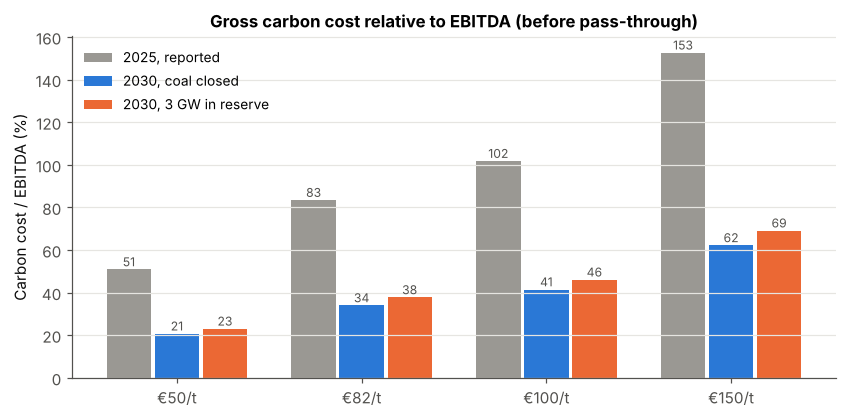

In [35]:
fig, ax = plt.subplots(figsize=(7.8, 3.9))
xx = np.arange(len(PRICES))
wd = 0.26
for i, (col, lab, colr) in enumerate(zip(var_tab.columns, ["2025, reported", "2030, coal closed", "2030, 3 GW in reserve"],
                                         [C["muted"], C["blue"], C["orange"]])):
    vals = var_tab[col].to_numpy() * 100
    ax.bar(xx + (i - 1) * wd, vals, width=wd - 0.02, color=colr, label=lab)
    for xv, v in zip(xx + (i - 1) * wd, vals):
        ax.text(xv, v + 1.5, f"{v:.0f}", ha="center", fontsize=8, color=C["ink2"])
ax.set_xticks(xx, [f"€{p}/t" for p in PRICES])
ax.set(ylabel="Carbon cost / EBITDA (%)", title="Gross carbon cost relative to EBITDA (before pass-through)")
ax.legend(fontsize=9)
ax.grid(axis="x", visible=False)
plt.tight_layout()
savefig(fig, "g2_carbon_cost_ratio")
plt.show()

## 3.3 Energy is not firm capacity
Capacity credits for wind and solar follow the de-rating factors proposed by National Grid for the GB Capacity Market (offshore wind 12.1-14.6%, onshore 8.2-9%, solar 1.2-1.8%; Solar Power Portal, 2024); for coal and gas we assume 0.90. These are British values used as a proxy: Germany has no capacity market publishing equivalent factors, and German wind and solar may contribute differently at winter peak, so this section gives orders of magnitude only.

In [36]:
CREDIT = {"offshore": 0.13, "onshore": 0.085, "solar": 0.015, "coal": 0.90, "gas": 0.90}
firm_lost = coal_gw_main * CREDIT["coal"]
exp_by_tech = pipe.groupby("grp").exp_gw.sum()
firm_re = sum(exp_by_tech.get(k, 0) * CREDIT[k] for k in ["offshore", "onshore", "solar"])
firm_re_denl = sum(pipe[pipe.de_nl].groupby("grp").exp_gw.sum().get(k, 0) * CREDIT[k] for k in ["offshore", "onshore", "solar"])
firm_gas = NEW_GAS_GW * CREDIT["gas"]
firm = pd.Series({"firm capacity lost (coal)": firm_lost, "firm from new wind/solar (expected, worldwide)": firm_re,
                  "of which in Germany + Netherlands": firm_re_denl,
                  "firm from new H2-ready gas (GEM pipeline <= 2030)": firm_gas,
                  "net firm gap in DE + NL (GW)": firm_lost - firm_re_denl - firm_gas})
firm.round(2)

firm capacity lost (coal)                           7.13
firm from new wind/solar (expected, worldwide)      0.62
of which in Germany + Netherlands                   0.14
firm from new H2-ready gas (GEM pipeline <= 2030)   1.60
net firm gap in DE + NL (GW)                        5.39
dtype: float64

In Germany and the Netherlands, where the coal closes, the new firm capacity from RWE's own projects is a fraction of what the coal provides. The gap has to be closed by the ~3 GW of gas plants RWE plans in North Rhine-Westphalia (tenders in September and December 2026), batteries, demand flexibility, imports and other producers. This is exactly the question behind the possible 2030-2033 reserve, and it is a **system** question, not something RWE's pipeline can answer alone.

---
# Part 4. Conclusion

In [37]:
print(c1[["rounded", "likelihood", "C1 pass (P >= 0.66)"]].to_string())
print()
print(hist_pace[["best 3-year average", "required / best (end of 2030 (5 years))", "C2 pass (end-2030 timing)"]].round(2).to_string())

                                                      rounded              likelihood  C1 pass (P >= 0.66)
Current plan, GEM-visible, end 2030                      0.00  exceptionally unlikely                False
Current plan, coverage-adjusted, end 2030                0.00  exceptionally unlikely                False
Current plan, GEM-visible, online before 31 Mar 2030     0.00  exceptionally unlikely                False
Full delivery, GEM-visible, end 2030                     0.55  about as likely as not                False
Full delivery, coverage-adjusted, end 2030               0.85                  likely                 True

                                             best 3-year average  required / best (end of 2030 (5 years))  C2 pass (end-2030 timing)
GEM-visible                                                 1.26                                     1.78                      False
coverage-adjusted                                           1.95                           

### Answer
* **C1 is not met on identifiable projects.** Under the *Current plan*, RWE's expected new wind and solar output in 2030 covers about half of the coal output it gives up (median 0.51, 90% interval 0.31-0.72; 0.57 coverage-adjusted). C1 only passes if everything with a planned start before 2030 is built and GEM's coverage gap is corrected (*Full delivery*, coverage-adjusted: P ≈ 0.85).
* **C2 narrowly fails on the decisive basis.** About 2.2 GW/yr is needed (2.6 GW/yr to be online by 31 March 2030). On the coverage-adjusted basis this is 1.14 times RWE's best 3-year average; it is 1.8 times the GEM-visible record and 0.93 times RWE's reported 2024-25 commissioning, which includes batteries. Removing pre-2023 US assets (mostly acquired) from the history makes the gap larger (1.9 times). In the **V0 wording** of H0, the pace implied by the identifiable pipeline (1.15 GW/yr) is within RWE's history (0.78-1.26 GW/yr GEM-visible): RWE is not planning to build faster than it has, it is planning *too little* that can be identified.
* **H0 cannot be supported on identifiable projects.** This verdict depends on a choice we make explicit: undated projects (two thirds of the pipeline MW in GEM) are excluded from the main case. Part of the gap is therefore a data gap, and the conclusion would change if RWE published a dated project list consistent with its guidance (≈ 3.2 GW/yr, ratio ≈ 1.4 if all wind and solar).
* **The target versus the delivery.** RWE's coal timeline is aligned with the IEA Net Zero milestone for advanced economies; what is not aligned, on identifiable projects, is the replacement.
* **Geography.** In Germany and the Netherlands, where the coal closes, RWE's own expected new output covers about 11% of its coal output. Replacing Rhineland lignite is mainly a system question (other producers, imports, flexibility), which is also why firm capacity is the real issue behind the possible 2030-2033 reserve.

### Extensions
* **SBTi intensity target.** RWE publishes 0.55 tCO₂e/MWh for 2022, so the 2030 target is 0.159. Our model reproduces RWE's published 2025 intensity well (0.44 vs 0.43), and **under our model assumptions** the 2030 intensity is 0.19-0.22 tCO₂e/MWh with coal closed on time, above the target in every scenario. The driver is the gas fleet (≈ 17 GW): at a gas capacity factor of 0.30 the intensity is still about 0.18. This verdict rests on a calibration on five points and on constant gas utilisation, so it should be read as "the target requires lower gas utilisation or more renewables than our scenarios contain", not as a firm prediction.
* **Carbon cost relative to EBITDA** falls from ≈ 83% (2025, €82/t) to ≈ 34% in 2030 once coal closes (vs 2027 EBITDA guidance). It is a flow ratio, gross of pass-through and of the €2.6 bn exit compensation, not a value-at-risk.
* **Firm capacity.** In Germany and the Netherlands RWE loses ≈ 7.1 GW of firm capacity; its own new wind, solar and gas in GEM replace ≈ 1.7 GW (British de-rating factors used as a proxy).

### Recommendations (sustainability consultant)
1. **Investors:** judge RWE on named, dated projects rather than portfolio targets. Track: (a) FID of Norfolk Vanguard (targeted for summer 2026, not publicly confirmed as of 8 November 2026) and progress of Nordseecluster B, (b) commissioned GW per year against ≈ 2.2 GW/yr, (c) the share of the 2031 guidance attached to identified projects.
2. **RWE:** a dated 2026-2030 project list would close most of the credibility gap we measure; the SBTi intensity target also needs a plan for gas utilisation, including the new hydrogen-ready plants.
3. **Policymakers:** the coal exit is legally fixed, but German firm capacity after 2030 is not secured by RWE's renewables. Timely flexible-capacity tenders are the lever; a 2030-2033 lignite reserve adds emissions and carbon exposure.

### Limitations
* GEM ownership coverage (≈ 64%) and a mostly undated pipeline: our main case is a lower bound by construction.
* Sector build rates use resolved projects only (censoring), are global, and ignore RWE's own delivery capacity; the slippage factor (0.8), the offshore probabilities (Vanguard 0.6, Nordseecluster B 0.85) and the correlations (ρ = 0.5 / 0.3) are assumptions. Europe-only and RWE-specific rates give medians of 0.49 and 0.51.
* The calibration uses five official years (B = 0.92, 90% CI 0.83-1.02); B is drawn in the Monte Carlo, but applying it to output as well as emissions assumes the model error is mostly utilisation.
* The back-test shows that simple 90% intervals undercover; ours are probably still too narrow.
* The history is a back-projection of today's portfolio and includes acquisitions; capacity factors are constant per technology.
* The IEA benchmark uses global all-renewables multipliers (including hydro); a European per-technology trajectory would be more appropriate.

### Changes since our V0 project definition
* **Denominator.** V0 planned coal + gas + oil. RWE has no dated gas exit (it is building new hydrogen-ready gas plants), so the commitment we test is the coal exit; the full-fossil version is a sensitivity.
* **Consolidation.** Equity share (RWE's economic exposure); operational control is a sensitivity (GKM Mannheim drops out).
* **Data.** GEM September 2026 V2 instead of August 2026; ENTSO-E capacity factors replaced by calibration on RWE's reported emissions and generation (we could not set up the ENTSO-E API in time).
* **Hypothesis.** H0 is evaluated through two criteria set after the V0 feedback, before the final analysis; H0 in its V0 wording is reported as well.
* **Benchmark.** IEA Renewables 2025 main and accelerated cases and the tripling pathway, pro rata to RWE's 2022 capacity, plus the IEA NZE coal milestone.


### Use of AI tools
We used an AI assistant (Claude, Anthropic) to help write and debug code, draft parts of the text and build the app and website. All modelling choices, sources and results were checked by the team.

---
# Part 5. Export for the Streamlit app and the website

In [38]:
pipe_out = pipe[["name", "Country/area", "grp", "Status", "cod", "gw", "p_main", "p_full", "p_undated", "is_off_ev",
                 "in_exit", "de_nl", "evidence", "source"]].rename(columns={"Country/area": "country", "grp": "tech", "Status": "status"})
pipe_out["is_con"] = pipe_out.status.eq("construction") & ~pipe_out.is_off_ev
pipe_out.to_csv(OUT / "rwe_pipeline_units.csv", index=False)
coal[["label", "kind", "Capacity (MW)", "w", "coal_mw", "Start year", "Retired year", "close_contract", "close_reserve",
      "is_reserve_unit", "corrected"]].to_csv(OUT / "rwe_coal_units.csv", index=False)
hist.to_csv(OUT / "rwe_history.csv", index=False)
scen.reset_index().to_csv(OUT / "scenario_summary.csv", index=False)
sens.to_csv(OUT / "sensitivities.csv")
ctry.to_csv(OUT / "europe_country_gap.csv", index=False)
peers.to_csv(OUT / "peers_europe.csv", index=False)
plants.to_csv(OUT / "europe_coal_plants_exposure.csv", index=False)
gap.to_csv(OUT / "intensity_gap.csv", index=False)
em_paths.to_csv(OUT / "emission_paths.csv", index=False)
calib.to_csv(OUT / "emissions_calibration.csv")
var_tab.to_csv(OUT / "carbon_cost_ratio.csv")
ev_tab.to_csv(OUT / "offshore_evidence.csv", index=False)
hist_pace.to_csv(OUT / "criterion_c2.csv")
c1.to_csv(OUT / "criterion_c1.csv")
iea.reset_index().to_csv(OUT / "iea_benchmark.csv", index=False)
metric.to_csv(OUT / "metric_perimeters.csv")

params = {
    "source": "GEM Global Integrated Power Tracker, September 2026 V2 (CC BY 4.0)",
    "target": TARGET, "now": NOW, "N": N, "H_YEAR": H_YEAR, "cf_range": CF_RANGE, "cf_mode": CF_MODE, "ef": EF,
    "B": B, "coal_cf_eff": COAL_CF_EFF, "build_rate": BUILD_RATE, "on_time": ON_TIME, "p_con": P_CON, "rho": RHO,
    "cap_now": cap_now, "old_retiring": old, "coverage": COVERAGE, "reported_2024": RWE_REPORTED_2024,
    "coal_gw_main": coal_gw_main, "coal_gw_noeems": coal_gw_noeems, "coal_gw_nogkm": coal_gw_nogkm, "coal_twh": COAL_TWH,
    "gas_gw": GAS_GW_NOW, "new_gas_gw": NEW_GAS_GW, "need_new_gw": need_new_gw, "req_pace": req,
    "pace": pace.to_dict(), "hist_additions_last10": last10.tolist(), "pipe_cf": pipe_cf,
    "int_2022": INT_2022, "int_target": INT_TARGET, "ebitda_2025": EBITDA_2025, "ebitda_2027": EBITDA_2027,
    "prices": PRICES, "credit": CREDIT, "firm": firm.to_dict(), "eu_ratio": eu_ratio,
    "metric": metric.to_dict(), "iea_mult": IEA_MULT, "cap22": cap22,
    "scenarios": scen.reset_index().to_dict(orient="records"),
    "c1": c1.reset_index().to_dict(orient="records"), "c2": hist_pace.reset_index().to_dict(orient="records"),
    "mix_now": mix.to_dict(), "guidance_pace": guid_pace, "guidance_ratio": guid_ratio, "existing_re_2030_twh": existing_re_2030, "other_re_twh": OTHER_RE_TWH,
}
(OUT / "params.json").write_text(json.dumps(params, indent=1, default=float))
print("exported:", sorted(p.name for p in OUT.iterdir()))

exported: ['carbon_cost_ratio.csv', 'climate_var.csv', 'criterion_c1.csv', 'criterion_c2.csv', 'emission_paths.csv', 'emissions_calibration.csv', 'europe_coal_plants_exposure.csv', 'europe_country_gap.csv', 'europe_country_ratio.csv', 'iea_benchmark.csv', 'intensity_gap.csv', 'metric_perimeters.csv', 'offshore_evidence.csv', 'params.json', 'peers.csv', 'peers_europe.csv', 'rwe_coal_units.csv', 'rwe_history.csv', 'rwe_pipeline_units.csv', 'scenario_summary.csv', 'sensitivities.csv']
